<a href="https://colab.research.google.com/github/mdelgiudicechaves-art/Trabalho-PSP8---MVP-Final/blob/main/MVP_Final_PSP8_Marina_Chaves.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MVP — Espectroscopia de impedância para apoio à decisão em tecido mamário
**Universidade de Brasília | Departamento de Engenharia de Produção | Prof. André Luiz Marques Serrano**
PSP8 - Pipeline de dados em nuvem
Base: *Breast Tissue Impedance Measurements* (UCI Machine Learning Repository)

Este notebook é o **MVP unificado**: coleta → **Bronze** → **Silver** → **Gold** (esquema estrela) → catálogo de dados → qualidade → análise das perguntas **P1–P5** → discussão, autoavaliação e README.

| Onde roda | Camadas e tabelas | Persistência |
|---|---|---|
| **Google Colab / local** | DuckDB (`mvp.duckdb`) + Parquet por tabela, **o mesmo SQL** | Pasta de saída (ou Google Drive, com `MONTAR_DRIVE = True`) |

O ambiente é detectado sozinho. **Todos os números e textos de discussão são gerados pela execução** (nada digitado à mão), e as saídas ficam gravadas no `.ipynb`, de modo que o GitHub exibe os resultados sem precisar rodar.

### Como usar
1. **Colab:** *Ambiente de execução → Executar tudo*. Na célula de Coleta o Colab pede o upload do CSV (ou aponte `CSV_LOCAL_PATH` para o arquivo no Drive).
2. Ao final: `mvp_unb_resultados.zip` (figuras, catálogo, tabelas, JSON e um **README.md** rascunho). Para a prova de nuvem do PDF, rode no Databricks e capture as evidências (seção 12).

| Critério (PDF §7) | Pts | Seção deste notebook |
|---|---|---|
| Objetivo | 1,0 | 1 |
| Coleta | 0,5 | 3 (data, volume, formato, hash, persistência) |
| Modelagem + Catálogo/linhagem | 2,0 | 7 (Gold, esquema estrela) e 8 (catálogo) |
| Carga (ETL) | 1,0 | 4 (Bronze), 6 (Silver), 7 (Gold) com regras explícitas |
| Análise: qualidade · solução · discussão | 3,0 | 5 · 9 (P1–P5) · discussões geradas |
| Autoavaliação | 0,5 | 11 |
| Capricho | 2,0 | organização, gráficos legíveis, README gerado |

### Índice do Notebook
1. Objetivo · 2. Configuração · 3. Coleta · 4. Bronze · 5. Qualidade · 6. Silver · 7. Gold · 8. Catálogo · 9. Análise P1–P5 · 10. Ética/LGPD · 11. Discussão geral e autoavaliação · 12. Exportação e evidências

## 1. Objetivo, perguntas de negócio e origem dos dados

**Problema.** A caracterização de tecido mamário depende de biópsia e histologia: é invasiva, lenta e cara. A **espectroscopia de impedância elétrica** mede, em tecido excisado, curvas de impedância por frequência de maneira rápida e barata. A questão de decisão é: *as medidas de impedância contêm informação suficiente para apoiar a triagem entre tipos de tecido, em particular a sinalização de carcinoma, e quais medidas valem a pena coletar?*

**Hipótese.** Tecidos diferentes têm assinaturas de impedância distintas; algumas variáveis são redundantes; carcinoma pode ser sinalizado com alta sensibilidade, e a separação entre tecidos benignos/normais parecidos (por exemplo fibroadenoma, mastopatia e glandular) é mais difícil.

**Perguntas de negócio** (mantidas integralmente, mesmo que alguma não seja totalmente respondida):

- **P1.** Quais atributos de impedância mais diferenciam os seis tipos de tecido e quais são redundantes entre si?
- **P2.** Os seis tipos de tecido são separáveis por aprendizado supervisionado? Qual o desempenho (validação cruzada repetida e aninhada) e quais pares de tecidos são confundidos?
- **P3.** É possível triar **carcinoma × não carcinoma** com sensibilidade ≥ 90%? A que custo de especificidade, e qual seria o valor preditivo em prevalências realistas (1%, 5%, 20%)?
- **P4.** Os dados formam grupos naturais (aprendizado não supervisionado)? Eles coincidem com os tipos de tecido ou com o agrupamento em 3 grupos citado na literatura do dataset?
- **P5.** Quantas e quais variáveis bastam? Existe uma regra simples e interpretável (árvore rasa) com desempenho próximo ao do melhor modelo?

**Decisão apoiada.** Definir se vale prosseguir com a espectroscopia de impedância como **teste de apoio** (não substitui a histologia), qual o conjunto mínimo de variáveis a coletar e qual o ponto de operação (limiar) para triagem de carcinoma.

**As três dimensões de um projeto inovador (PDF §1.2).**

| Dimensão | Pergunta | Evidência neste MVP |
|---|---|---|
| Viabilidade técnica | Dá para construir com a tecnologia disponível? | Pipeline Bronze→Silver→Gold→análise executando ponta a ponta na nuvem |
| Viabilidade financeira | É economicamente sustentável? | Tempo de execução por etapa e volume de dados (seção 12): custo de operação estimado |
| Desejabilidade | É o que o usuário quer? | P2–P5 respondidas com dados e discutidas criticamente (sensibilidade × especificidade) |

**Origem dos dados.** UCI Machine Learning Repository — *Breast Tissue* (J. Jossinet, 1996; ref.: *Variability of impedivity in normal and pathological breast tissue*, Med. & Biol. Eng. & Comput. 34, 346–350). São 106 amostras de tecido mamário excisado, 9 atributos numéricos derivados do espectro de impedância e 1 classe com 6 categorias (`car` carcinoma, `fad` fibroadenoma, `mas` mastopatia, `gla` glandular, `con` conjuntivo, `adi` adiposo). **Licença:** registrada na seção 2 e conferida pelo aluno (o dataset é divulgado pelo UCI como CC BY 4.0; *confirme na página de onde baixou o arquivo*).

> **Aviso.** Trabalho acadêmico. Os resultados **não** têm validade clínica e não devem ser usados para diagnóstico.

## 2. Configuração (única célula de parâmetros)

In [1]:
# ============================ CONFIGURAÇÃO ÚNICA ============================
import os
# --- Dados -------------------------------------------------------------------
CSV_NAME_PADRAO = "Breast Tissue Impedance Measurements - Data.csv"
CSV_LOCAL_PATH = os.environ.get("MVP_CSV_LOCAL", "")
FONTE_DADOS = "UCI Machine Learning Repository - Breast Tissue (Jossinet, 1996)"
LICENCA_DADOS = "CC BY 4.0 (UCI)"
DATA_CONFERENCIA_LICENCA = "11/11/2026"

# --- Colab -------------------------------------------------------------------
MONTAR_DRIVE = False        # True = copia a saída para o Google Drive (persistência em nuvem no Colab)
BAIXAR_ZIP_COLAB = True     # True = baixa o .zip de resultados ao final (só Colab)

# --- Parâmetros de modelagem e de regras ---------------------------------------
SEED = 42
N_SPLITS, N_REPEATS = 5, 10     # validação cruzada estratificada repetida (5 x 10 = 50 dobras)
N_REPEATS_P5 = 3                # repetições de P5 (importância e curva de variáveis)
N_BOOT = 1000                   # reamostragens bootstrap dos intervalos de confiança (P3)
SENSIBILIDADE_ALVO = 0.90       # P3: sensibilidade mínima desejada para carcinoma
PREVALENCIAS = [0.01, 0.05, 0.20]   # P3: prevalências hipotéticas para o valor preditivo
TOL_PARSIMONIA = 0.02           # P5: perda aceitável de macro-F1 ao reduzir variáveis
REMOVER_DUPLICATAS = True       # False = mantém linhas repetidas (apenas sinaliza)

# --- Perguntas de negócio (as mesmas da seção 1; usadas no README gerado)
PERGUNTAS = [
    ('P1', 'Quais atributos de impedância mais diferenciam os seis tipos de tecido e quais são redundantes entre si?'),
    ('P2', 'Os seis tipos de tecido são separáveis por aprendizado supervisionado? Qual o desempenho (validação cruzada repetida e aninhada) e quais pares de tecidos são confundidos?'),
    ('P3', 'É possível triar **carcinoma × não carcinoma** com sensibilidade ≥ 90%? A que custo de especificidade, e qual seria o valor preditivo em prevalências realistas (1%, 5%, 20%)?'),
    ('P4', 'Os dados formam grupos naturais (aprendizado não supervisionado)? Eles coincidem com os tipos de tecido ou com o agrupamento em 3 grupos citado na literatura do dataset?'),
    ('P5', 'Quantas e quais variáveis bastam? Existe uma regra simples e interpretável (árvore rasa) com desempenho próximo ao do melhor modelo?'),
]

In [2]:
# Dependências leves (já presentes no Colab/Databricks; instala só o que faltar)
import importlib, subprocess, sys
def _garantir(pacote, modulo=None):
    try:
        importlib.import_module(modulo or pacote)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--root-user-action=ignore", pacote],
                       check=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
if "spark" not in globals():      # fora do Databricks usamos DuckDB
    _garantir("duckdb")

### 2.1 Ambiente: Colab/local (DuckDB + Parquet)
A célula abaixo detecta o ambiente e define **quatro funções** usadas no resto do notebook: `T(nome)` (nome qualificado da tabela), `sql(consulta)` (devolve pandas), `sql_exec(comando)` e `salvar_tabela(df, nome)`. Assim, **o mesmo SQL** roda em Spark SQL e em DuckDB.

In [3]:
# ---------- AMBIENTE ---------------------------------------------------------
import os, sys, json, hashlib, uuid, shutil, time, warnings, datetime as dt
from contextlib import contextmanager
from pathlib import Path
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

try:
    spark  # noqa: F821  (existe só no Databricks)
    AMBIENTE = "databricks"
except NameError:
    AMBIENTE = "colab" if Path("/content").exists() else "local"

try:
    display  # noqa: F821
except NameError:
    from IPython.display import display

TEMPOS = {}
@contextmanager
def etapa(nome):
    """Cronometra uma etapa do pipeline (insumo da viabilidade financeira, seção 12)."""
    t0 = time.perf_counter()
    try:
        yield
    finally:
        TEMPOS[nome] = TEMPOS.get(nome, 0.0) + time.perf_counter() - t0

# Pasta de trabalho local (sempre gravável). No fim, persistir_saida() copia para o Volume/Drive.
if AMBIENTE == "databricks":
    SAIDA = Path("/tmp/mvp_impedancia/saida")
    VOLUME_PATH = Path(f"/Volumes/{CATALOG}/{SCHEMA}/{VOLUME}")
elif AMBIENTE == "colab":
    SAIDA = Path("/content/mvp_impedancia/saida")
    VOLUME_PATH = None
    if MONTAR_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
else:
    SAIDA = Path("mvp_impedancia") / "saida"
    VOLUME_PATH = None
EVID, CAT, TAB, DADOS = SAIDA / "evidencias", SAIDA / "catalogo", SAIDA / "tabelas", SAIDA / "dados"
for _p in (EVID, CAT, TAB, DADOS):
    _p.mkdir(parents=True, exist_ok=True)

if AMBIENTE == "databricks":
    def T(nome):
        return f"{CATALOG}.{SCHEMA}.{nome}"
    def sql(q):
        return spark.sql(q).toPandas()
    def sql_exec(q):
        spark.sql(q)
    def salvar_tabela(df, nome):
        d = df.copy()
        for c in d.columns:
            if str(d[c].dtype) == "category":
                d[c] = d[c].astype(str)
        (spark.createDataFrame(d).write.mode("overwrite").option("overwriteSchema", "true")
              .format("delta").saveAsTable(T(nome)))
    def preparar_camada():
        spark.sql(f"CREATE SCHEMA IF NOT EXISTS {CATALOG}.{SCHEMA}")
        spark.sql(f"CREATE VOLUME IF NOT EXISTS {CATALOG}.{SCHEMA}.{VOLUME}")
else:
    import duckdb
    _db = SAIDA / "mvp.duckdb"
    con = duckdb.connect(str(_db))
    def T(nome):
        return nome
    def sql(q):
        return con.execute(q).fetchdf()
    def sql_exec(q):
        con.execute(q)
    def salvar_tabela(df, nome):
        con.register("_tmp_df", df)
        con.execute(f"CREATE OR REPLACE TABLE {nome} AS SELECT * FROM _tmp_df")
        con.unregister("_tmp_df")
        try:
            df.to_parquet(TAB / f"{nome}.parquet", index=False)
        except Exception as e:
            print("Parquet não gravado para", nome, "->", repr(e)[:80])
    def preparar_camada():
        pass

def ler_tabela(nome):
    return sql(f"SELECT * FROM {T(nome)}")

def persistir_saida():
    """Copia a pasta de saída para a nuvem: Volume (Databricks) ou Google Drive (Colab com MONTAR_DRIVE)."""
    destino = None
    if AMBIENTE == "databricks":
        destino = VOLUME_PATH / "saida"
    elif AMBIENTE == "colab" and MONTAR_DRIVE:
        destino = Path("/content/drive/MyDrive/mvp_impedancia/saida")
    if destino is None:
        return None
    try:
        shutil.copytree(SAIDA, destino, dirs_exist_ok=True)
        return destino
    except Exception as e:
        print("Aviso: não foi possível persistir em", destino, "->", repr(e)[:150])
        return None

preparar_camada()
print(f"Ambiente: {AMBIENTE} | pasta de trabalho: {SAIDA}")
if AMBIENTE == "databricks":
    print(f"Schema/Volume prontos: {CATALOG}.{SCHEMA} / {VOLUME_PATH}")
    print("-> Se ainda não enviou o CSV, faça upload no Volume acima antes de executar a Coleta.")

Ambiente: colab | pasta de trabalho: /content/mvp_impedancia/saida


### 2.2 Núcleo de lógica: constantes, formatação e funções reutilizáveis
Dicionário de tecidos e atributos (usados no Gold e no catálogo) e utilitários de formatação em pt-BR.

In [4]:
# ============================================================
# NÚCLEO — constantes, mapeamentos e utilitários
# ============================================================
from IPython.display import Markdown
import re

CLASSES = ["car", "fad", "mas", "gla", "con", "adi"]     # ordem do arquivo
FEATURES = ["i0", "pa500", "hfs", "da", "area", "a_da", "max_ip", "dr", "p_curva"]
RENOMEAR = {"Class": "classe", "I0": "i0", "PA500": "pa500", "HFS": "hfs", "DA": "da", "Area": "area",
            "A_DA": "a_da", "Max_IP": "max_ip", "DR": "dr", "P": "p_curva"}

# Dimensão tecido. A categoria clínica e o agrupamento em 3 grupos são rótulos de apoio (ver seção 7);
# o agrupamento "grupo_uci" é verificado com os dados em P2 e P4.
TECIDOS = pd.DataFrame([
    ("car", "Carcinoma",    "Carcinoma",      "Maligno", "G1 carcinoma"),
    ("fad", "Fibroadenoma", "Fibro-adenoma",  "Benigno", "G2 fad+mas+gla"),
    ("mas", "Mastopatia",   "Mastopathy",     "Benigno", "G2 fad+mas+gla"),
    ("gla", "Glandular",    "Glandular",      "Normal",  "G2 fad+mas+gla"),
    ("con", "Conjuntivo",   "Connective",     "Normal",  "G3 con+adi"),
    ("adi", "Adiposo",      "Adipose",        "Normal",  "G3 con+adi"),
], columns=["classe", "tecido_pt", "tecido_en", "categoria_clinica", "grupo_uci"])
TECIDOS.insert(0, "tecido_id", range(1, len(TECIDOS) + 1))
NOME_TECIDO = dict(zip(TECIDOS["classe"], TECIDOS["tecido_pt"]))
GRUPO_UCI = dict(zip(TECIDOS["classe"], TECIDOS["grupo_uci"]))

ATRIBUTOS = pd.DataFrame([
    ("i0",      "I0",     "Impedividade em frequência zero",              "Ω",   "Impedividade (I0) na frequência zero do espectro",                                  "> 0"),
    ("pa500",   "PA500",  "Ângulo de fase a 500 kHz",                     "rad", "Ângulo de fase (PA500) medido a 500 kHz (unidade inferida pela faixa de valores)",  "0 a π/2 (≈ 1,571)"),
    ("hfs",     "HFS",    "Inclinação de alta frequência do ângulo de fase", "—", "Inclinação do ângulo de fase na região de alta frequência (HFS)",                   "livre (pode ser negativa)"),
    ("da",      "DA",     "Distância de impedância entre extremidades",   "—",   "Distância de impedância entre as extremidades do espectro (DA)",                     "> 0"),
    ("area",    "Area",   "Área sob o espectro",                          "—",   "Área sob o espectro de impedância",                                                  ">= 0"),
    ("a_da",    "A.DA",   "Área normalizada por DA",                      "—",   "Área normalizada pela distância DA (Area / DA)",                                     "> 0 e = area/da"),
    ("max_ip",  "Max.IP", "Máximo do espectro",                           "—",   "Valor máximo do espectro de impedância (Max IP)",                                    "> 0"),
    ("dr",      "DR",     "Distância I0 – ponto de frequência máxima",    "—",   "Distância entre I0 e a parte real do ponto de frequência máxima (DR)",               "<= da (raramente < 0)"),
    ("p_curva", "P",      "Comprimento da curva espectral",               "—",   "Comprimento da curva do espectro (P)",                                               ">= da"),
], columns=["coluna", "nome_original", "nome_pt", "unidade", "descricao", "regra_dominio"])
ATRIBUTOS.insert(0, "atributo_id", range(1, len(ATRIBUTOS) + 1))
ROTULO = dict(zip(ATRIBUTOS["coluna"], ATRIBUTOS["nome_original"]))   # rótulo curto para gráficos

def br(x, n=2):
    s = f"{x:,.{n}f}"
    return s.replace(",", "§").replace(".", ",").replace("§", ".")
def pct(x, n=1):
    return br(100 * x, n) + "%"

def _md_para_html(t):
    out, em_lista = [], False
    for ln in t.split("\n"):
        ln2 = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", ln)
        ln2 = re.sub(r"(?<!\*)\*(?!\*)(.+?)(?<!\*)\*(?!\*)", r"<i>\1</i>", ln2)
        ln2 = re.sub(r"`(.+?)`", r"<code>\1</code>", ln2)
        if ln2.startswith("- "):
            if not em_lista:
                out.append("<ul>"); em_lista = True
            out.append("<li>" + ln2[2:] + "</li>")
            continue
        if em_lista:
            out.append("</ul>"); em_lista = False
        if ln2.startswith("### "):
            out.append("<h4>" + ln2[4:] + "</h4>")
        elif ln2.strip():
            out.append("<p>" + ln2 + "</p>")
    if em_lista:
        out.append("</ul>")
    return "\n".join(out)

DISCUSSOES = []      # textos "### ..." gerados; reaproveitados no README
def mostrar_md(t):
    """Renderiza markdown no Colab/Jupyter e, no Databricks, converte para HTML."""
    if t.startswith("### "):
        DISCUSSOES.append(t)
    if AMBIENTE == "databricks":
        displayHTML(_md_para_html(t))  # noqa: F821
    else:
        display(Markdown(t))

## 3. Coleta
Ordem de tentativa: **(1)** arquivo informado em `CSV_LOCAL_PATH`; **(2)** arquivo já existente (Volume do Databricks, pasta atual, `/content`, Drive); **(3)** upload manual (Colab).

O código registra **data, linhas/colunas, tamanho e hash sha256** do arquivo, a base da reprodutibilidade (seção 3.2 do PDF). No Databricks o CSV bruto fica **persistido no Volume**; no Colab, na pasta de saída (e no Drive, se `MONTAR_DRIVE`).

In [5]:
def localizar_csv():
    pastas = [Path.cwd(), Path("/content"), Path("/content/drive/MyDrive"), DADOS]
    if AMBIENTE == "databricks":
        pastas = [VOLUME_PATH] + pastas
    cands = []
    if CSV_LOCAL_PATH:
        cands.append(Path(CSV_LOCAL_PATH))
    for p in pastas:
        if p is not None and p.exists():
            cands.append(p / CSV_NAME_PADRAO)
            cands += sorted(p.glob("*[Bb]reast*[Tt]issue*.csv"))
    for c in cands:
        if c.exists():
            return c
    return None

with etapa("Coleta"):
    arq = localizar_csv()
    origem = "arquivo já existente"
    if arq is None and AMBIENTE == "colab":
        from google.colab import files
        print("Selecione o CSV da base (Breast Tissue Impedance Measurements)...")
        up = files.upload()
        nome_up = next(iter(up))
        arq = Path("/content") / nome_up
        arq.write_bytes(up[nome_up]); origem = "upload manual (Colab)"
    if arq is None:
        raise FileNotFoundError(
            "CSV não encontrado. Databricks: envie o arquivo para o Volume " + str(VOLUME_PATH) +
            " (Catalog > Upload to this volume). Local: defina CSV_LOCAL_PATH ou MVP_CSV_LOCAL.")

    destino = DADOS / arq.name
    if arq.resolve() != destino.resolve():
        shutil.copy(arq, destino)
    if AMBIENTE == "databricks" and arq.parent != VOLUME_PATH:
        shutil.copy(arq, VOLUME_PATH / arq.name)        # bruto persistido no Volume (nuvem)

    sha = hashlib.sha256(destino.read_bytes()).hexdigest()
    amostra = pd.read_csv(destino, dtype=str)
    esperadas = ["Class", "I0", "PA500", "HFS", "DA", "Area", "A.DA", "Max.IP", "DR", "P"]
    assert list(amostra.columns) == esperadas, f"Colunas inesperadas: {list(amostra.columns)}"
    meta = {"data_coleta_utc": dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
            "origem_do_arquivo": origem, "arquivo": arq.name, "formato_original": "CSV (separador vírgula, UTF-8, aspas nos textos)",
            "linhas": int(len(amostra)), "colunas": int(amostra.shape[1]), "tamanho_bytes": int(destino.stat().st_size),
            "sha256": sha, "fonte": FONTE_DADOS, "licenca": LICENCA_DADOS,
            "data_conferencia_licenca": DATA_CONFERENCIA_LICENCA, "ambiente": AMBIENTE}
    (SAIDA / "coleta_metadados.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
pd.DataFrame(meta.items(), columns=["campo", "valor"])

,campo,valor
0,data_coleta_utc,2026-11-11T17:31:57Z
1,origem_do_arquivo,arquivo já existente
2,arquivo,Breast Tissue Impedance Measurements - Data.csv
3,formato_original,"CSV (separador vírgula, UTF-8, aspas nos textos)"
4,linhas,106
5,colunas,10
6,tamanho_bytes,16361
7,sha256,4d7d2601f6778db979e922b3ac115e67ff2a5a6b1dc19d...
8,fonte,UCI Machine Learning Repository - Breast Tissu...
9,licenca,CC BY 4.0 (UCI)


## 4. Bronze — dado bruto, sem alteração de conteúdo
Lê o CSV com **todas as colunas como texto** (sem inferência de tipos) e acrescenta metadados de ingestão: `_linha_origem` (posição da linha no arquivo, base 1, que vira o identificador da amostra), `_ingestao_ts`, `_arquivo_origem` e `_lote_id`. A única mudança é **sanitizar o nome das colunas** (`A.DA` → `A_DA`, `Max.IP` → `Max_IP`), porque pontos em nomes de colunas atrapalham o SQL e o Delta. A Bronze **preserva todos os registros**, inclusive repetidos.

In [6]:
with etapa("Bronze"):
    bronze = pd.read_csv(destino, dtype=str)
    bronze.columns = [c.replace(".", "_").replace(" ", "_") for c in bronze.columns]
    bronze["_linha_origem"] = np.arange(1, len(bronze) + 1)
    bronze["_ingestao_ts"] = pd.Timestamp.now().floor("s")
    bronze["_arquivo_origem"] = arq.name
    bronze["_lote_id"] = str(uuid.uuid4())
    assert len(bronze) == meta["linhas"] and bronze.shape[1] == meta["colunas"] + 4, "Bronze não confere com o CSV"
    salvar_tabela(bronze, "bronze_impedancia")
print(f"Tabela criada: {T('bronze_impedancia')} | {len(bronze)} linhas × {bronze.shape[1]} colunas (com metadados)")
display(sql(f"SELECT COUNT(*) AS linhas FROM {T('bronze_impedancia')}"))
bronze.head(5)

Tabela criada: bronze_impedancia | 106 linhas × 14 colunas (com metadados)


,linhas
0,106


,Class,I0,PA500,HFS,DA,Area,A_DA,Max_IP,DR,P,_linha_origem,_ingestao_ts,_arquivo_origem,_lote_id
0,car,524.794071957203,0.187448361664191,0.0321140582366957,228.800227884333,6843.59848118909,29.9108027315811,60.2048797607422,220.737212005168,556.828334181036,1,2026-11-11 17:31:57,Breast Tissue Impedance Measurements - Data.csv,9002e18a-707e-40ac-a74c-9a7e5395f9f7
1,car,330,0.226892802759263,0.265290046303138,121.154200670845,3163.23947199462,26.1092017815263,69.7173614501953,99.0849640002901,400.225775982673,2,2026-11-11 17:31:57,Breast Tissue Impedance Measurements - Data.csv,9002e18a-707e-40ac-a74c-9a7e5395f9f7
2,car,551.879287398478,0.232477856365645,0.0635299847725935,264.804935429954,11888.3918269139,44.8949027615785,77.7932968139648,253.785299778118,656.769449402464,3,2026-11-11 17:31:57,Breast Tissue Impedance Measurements - Data.csv,9002e18a-707e-40ac-a74c-9a7e5395f9f7
3,car,380,0.240855436775217,0.28623399732707,137.640110855262,5402.17118040177,39.2485238992762,88.7584457397461,105.198568047696,493.701813502438,4,2026-11-11 17:31:57,Breast Tissue Impedance Measurements - Data.csv,9002e18a-707e-40ac-a74c-9a7e5395f9f7
4,car,362.831265909976,0.200712863979348,0.244346095279206,124.912559369246,3290.46244627658,26.3421265474985,69.3893890380859,103.866551881876,424.796503386825,5,2026-11-11 17:31:57,Breast Tissue Impedance Measurements - Data.csv,9002e18a-707e-40ac-a74c-9a7e5395f9f7


## 5. Análise de qualidade de dados (por atributo)
Dimensões examinadas (PDF §3.5a): **completude** (nulos), **unicidade** (duplicatas e conflitos de rótulo), **conformidade** (aderência ao domínio), **consistência** (relações matemáticas entre atributos), **acurácia** (valores implausíveis, outliers) e **atualidade**.

Duas relações são verificáveis pela própria definição dos atributos: `A.DA = Area / DA` (área normalizada) e `P ≥ DA` (o comprimento de uma curva não pode ser menor que a distância entre suas extremidades).

In [7]:
# ---------- QUALIDADE DE DADOS (sobre o dado bruto convertido) -----------------------------
def bronze_para_numerico(b):
    """Bronze (texto) -> DataFrame tipado, só para diagnóstico. A Silver repete a conversão com as regras de negócio."""
    d = b[[c for c in b.columns if not c.startswith("_")]].rename(columns=RENOMEAR).copy()
    for c in FEATURES:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    d.insert(0, "amostra_id", b["_linha_origem"].astype(int).values)
    return d

def outliers_intraclasse(d, k=3.0):
    """Marca valores além de k·IQR dentro da própria classe (outlier 'extremo' por tecido)."""
    flags = pd.DataFrame(False, index=d.index, columns=FEATURES)
    for _, g in d.groupby("classe"):
        q1, q3 = g[FEATURES].quantile(.25), g[FEATURES].quantile(.75)
        i = q3 - q1
        flags.loc[g.index, FEATURES] = ((g[FEATURES] < q1 - k * i) | (g[FEATURES] > q3 + k * i)).values
    return flags

def perfil_atributos(d):
    linhas = []
    for c in FEATURES:
        s = d[c]
        q1, q3 = s.quantile([.25, .75]); i = q3 - q1
        linhas.append({"atributo": c, "tipo": str(s.dtype), "nulos": int(s.isna().sum()), "% nulos": round(100 * s.isna().mean(), 2),
                       "únicos": int(s.nunique()), "mín": s.min(), "p25": q1, "mediana": s.median(), "p75": q3, "máx": s.max(),
                       "média": s.mean(), "desvio": s.std(), "assimetria": s.skew(),
                       "outliers_IQR(1,5)": int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())})
    return pd.DataFrame(linhas)

def testes_qualidade(d):
    F, T_ = d[FEATURES], []
    def add(dim, teste, n, nota="", status=None):
        T_.append({"dimensão": dim, "teste": teste, "afetados": int(n),
                   "status": status or ("OK" if n == 0 else "ALERTA"), "nota": nota})
    add("Completude", "Nulos em qualquer atributo ou na classe", F.isna().sum().sum() + d["classe"].isna().sum())
    add("Unicidade", "Linhas repetidas (todos os atributos e a classe)", d.duplicated(subset=FEATURES + ["classe"]).sum(),
        "linha extra além da primeira ocorrência; dupla contagem distorce médias e vaza informação na validação cruzada")
    conflito = d.groupby(FEATURES)["classe"].nunique().gt(1).sum()
    add("Unicidade", "Mesmas medidas com classes diferentes (conflito de rótulo)", conflito)
    add("Conformidade", "Classe fora das 6 categorias válidas", (~d["classe"].isin(CLASSES)).sum())
    add("Conformidade", "i0, da, max_ip, a_da ou p_curva <= 0", ((d[["i0", "da", "max_ip", "a_da", "p_curva"]] <= 0).any(axis=1)).sum())
    add("Conformidade", "area < 0", (d["area"] < 0).sum())
    add("Conformidade", "pa500 fora de [0, π/2]", ((d["pa500"] < 0) | (d["pa500"] > np.pi / 2)).sum())
    inc = ((d["a_da"] - d["area"] / d["da"]).abs() / d["a_da"] > 1e-6).sum()
    add("Consistência", "a_da diferente de area / da (tolerância relativa 1e-6)", inc)
    add("Consistência", "p_curva < da (curva menor que a distância entre extremidades)", (d["p_curva"] < d["da"]).sum())
    add("Consistência", "dr > da", (d["dr"] > d["da"] * (1 + 1e-9)).sum())
    add("Consistência", "dr < 0 (distância negativa)", (d["dr"] < 0).sum(),
        "mantido e sinalizado (flag_dr_negativo): pode ser diferença com sinal, não erro de medição")
    add("Consistência", "hfs < 0 (inclinação negativa)", (d["hfs"] < 0).sum(),
        "plausível: inclinação pode ser negativa; mantido", status="INFO")
    fl = outliers_intraclasse(d)
    add("Acurácia", "Linhas com algum valor além de 3·IQR dentro da própria classe", fl.any(axis=1).sum(),
        "valores extremos dentro do tecido; mantidos e sinalizados (análise robusta a outliers)")
    add("Atualidade", "Coluna de data/hora de medição", 0, "base estática de 1996, sem data de medição; atualidade não se aplica", status="N/A")
    return pd.DataFrame(T_)

raw = bronze_para_numerico(bronze)
perfil_q = perfil_atributos(raw)
perfil_q.to_csv(CAT / "qualidade_por_atributo.csv", index=False)
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 120)
perfil_q.round(3)

,atributo,tipo,nulos,% nulos,únicos,mín,p25,mediana,p75,máx,média,desvio,assimetria,"outliers_IQR(1,5)"
0,i0,float64,0,0.0,95,103.000,250.000,384.936,1487.990,2800.000,784.252,753.950,1.105,0
1,pa500,float64,0,0.0,105,0.012,0.067,0.105,0.170,0.358,0.120,0.069,0.891,1
2,hfs,float64,0,0.0,100,-0.066,0.044,0.087,0.167,0.468,0.115,0.101,1.120,4
3,da,float64,0,0.0,105,19.648,53.845,120.777,255.335,1063.441,190.569,190.801,1.783,7
4,area,float64,0,0.0,105,70.426,409.647,2219.581,7615.205,174480.476,7335.155,18580.314,7.270,8
5,a_da,float64,0,0.0,105,1.596,8.180,16.134,30.953,164.072,23.474,23.355,2.833,5
6,max_ip,float64,0,0.0,105,7.969,26.894,44.216,83.672,436.100,75.381,81.346,2.480,11
7,dr,float64,0,0.0,105,-9.258,41.781,97.833,232.990,977.552,166.711,181.310,1.851,7
8,p_curva,float64,0,0.0,105,124.979,270.215,454.108,1301.559,2896.582,810.638,763.019,1.240,1


In [8]:
qualidade = testes_qualidade(raw)
qualidade.to_csv(CAT / "qualidade_testes.csv", index=False)
qualidade

,dimensão,teste,afetados,status,nota
0,Completude,Nulos em qualquer atributo ou na classe,0,OK,
1,Unicidade,Linhas repetidas (todos os atributos e a classe),1,ALERTA,linha extra além da primeira ocorrência; dupla contagem distorce médias e vaza informação na validação cruzada
2,Unicidade,Mesmas medidas com classes diferentes (conflito de rótulo),0,OK,
3,Conformidade,Classe fora das 6 categorias válidas,0,OK,
4,Conformidade,"i0, da, max_ip, a_da ou p_curva <= 0",0,OK,
5,Conformidade,area < 0,0,OK,
6,Conformidade,"pa500 fora de [0, π/2]",0,OK,
7,Consistência,a_da diferente de area / da (tolerância relativa 1e-6),0,OK,
8,Consistência,p_curva < da (curva menor que a distância entre extremidades),0,OK,
9,Consistência,dr > da,0,OK,


In [9]:
# Detalhe das linhas repetidas e da distribuição por classe
cols_dup = FEATURES + ["classe"]
grupos_dup = (raw[raw.duplicated(subset=cols_dup, keep=False)].groupby(cols_dup)["amostra_id"].apply(list).reset_index(drop=True))
print(f"{len(grupos_dup)} grupo(s) de linhas repetidas. IDs de amostra (linha no arquivo) em cada grupo: {grupos_dup.tolist()}")
contagem = raw["classe"].value_counts().reindex(CLASSES)
print("Amostras por classe:", {NOME_TECIDO[c]: int(n) for c, n in contagem.items()})
print(f"Razão maior/menor classe = {contagem.max() / contagem.min():.2f} (classes razoavelmente balanceadas, mas todas pequenas)")

1 grupo(s) de linhas repetidas. IDs de amostra (linha no arquivo) em cada grupo: [[60, 61]]
Amostras por classe: {'Carcinoma': 21, 'Fibroadenoma': 15, 'Mastopatia': 18, 'Glandular': 16, 'Conjuntivo': 14, 'Adiposo': 22}
Razão maior/menor classe = 1.57 (classes razoavelmente balanceadas, mas todas pequenas)


## 6. Silver — tipagem, regras de negócio e sinalizações
| Regra | Decisão | Justificativa |
|---|---|---|
| **R1** Tipagem e nomes | Converter texto → `float`; nomes em *snake_case*; `amostra_id` = linha do arquivo | Bronze guarda tudo como texto; `Class` vira `classe` |
| **R2** Linha repetida | **Remover** da Silver (mantém a 1ª ocorrência); a Bronze preserva tudo. `REMOVER_DUPLICATAS=False` só sinaliza | A mesma medição contada duas vezes pesa mais nas estatísticas e, na validação cruzada, pode cair em treino e teste ao mesmo tempo (vazamento) |
| **R3** `dr < 0` | **Manter** e sinalizar (`flag_dr_negativo`) | Pode ser diferença com sinal; remover perderia uma amostra de classe pequena |
| **R4** Outliers extremos | **Manter** e sinalizar (`flag_outlier_extremo`, > 3·IQR dentro da classe) | São medidas fisicamente plausíveis (ex.: tecido adiposo tem escala muito maior); modelos usam transformação de potência e/ou são baseados em árvores |
| **R5** `hfs < 0` | Manter (apenas registrado) | Inclinação pode ser negativa |
| **R6** Domínio da classe | Validar as 6 categorias (falha o pipeline se houver outra) | Garante a integridade da dimensão tecido no Gold |
| Sem imputação | — | A base não tem nulos; nada a imputar |

In [10]:
# ---------- SILVER: tipagem, qualidade e sinalizações ---------------------------------
def silver_transform(b, remover_duplicatas=True):
    """Recebe a Bronze (texto) e devolve (silver, log, duplicatas). log = {regra, afetados, decisao}."""
    log = []
    d = bronze_para_numerico(b)
    log.append({"regra": "R1 Tipagem e nomes", "afetados": int(len(d)),
                "decisao": "Texto convertido para float; colunas em snake_case; amostra_id = linha do arquivo"})

    # R2. Linhas repetidas (mantém a de menor amostra_id)
    chaves = FEATURES + ["classe"]
    grupo = d.groupby(chaves, sort=False).ngroup()
    mantido = d.groupby(grupo)["amostra_id"].transform("min")
    extra = d[d["amostra_id"] != mantido]
    dup = pd.DataFrame({"amostra_id_removida": extra["amostra_id"].values, "amostra_id_mantida": mantido[extra.index].values})
    if remover_duplicatas and len(dup):
        d = d[~d["amostra_id"].isin(dup["amostra_id_removida"])].copy()
        acao = "Removidas da Silver (mantida a 1ª ocorrência); a Bronze preserva todos os registros"
    else:
        acao = "Mantidas (REMOVER_DUPLICATAS=False)"
    log.append({"regra": "R2 Linhas repetidas", "afetados": int(len(dup)), "decisao": acao})
    d = d.sort_values("amostra_id").reset_index(drop=True)

    # R3, R5. Sinalizações
    d["flag_dr_negativo"] = d["dr"] < 0
    log.append({"regra": "R3 dr < 0", "afetados": int(d["flag_dr_negativo"].sum()), "decisao": "Mantido; flag_dr_negativo = True"})
    log.append({"regra": "R5 hfs < 0", "afetados": int((d["hfs"] < 0).sum()), "decisao": "Mantido (inclinação pode ser negativa)"})

    # R4. Outliers extremos dentro da classe
    fl = outliers_intraclasse(d)
    d["flag_outlier_extremo"] = fl.any(axis=1).values
    log.append({"regra": "R4 Outliers extremos (3·IQR intraclasse)", "afetados": int(d["flag_outlier_extremo"].sum()),
                "decisao": "Mantidos; flag_outlier_extremo = True"})

    # R6. Domínio da classe
    assert d["classe"].isin(CLASSES).all(), "Classe fora do domínio"
    log.append({"regra": "R6 Domínio da classe", "afetados": 0, "decisao": "6 categorias válidas (car, fad, mas, gla, con, adi)"})
    colunas = ["amostra_id", "classe"] + FEATURES + ["flag_dr_negativo", "flag_outlier_extremo"]
    return d[colunas], pd.DataFrame(log), dup

with etapa("Silver"):
    silver, log_regras, duplicatas = silver_transform(bronze, remover_duplicatas=REMOVER_DUPLICATAS)
    n_esperado = len(bronze) - (len(duplicatas) if REMOVER_DUPLICATAS else 0)
    assert len(silver) == n_esperado, "Silver perdeu/duplicou linhas além das duplicatas removidas"
    assert silver["amostra_id"].is_unique, "amostra_id duplicado"
    assert silver[FEATURES].notna().all().all(), "Silver não deveria ter nulos"
    assert (silver[["i0", "da", "max_ip", "a_da", "p_curva"]] > 0).all().all()
    salvar_tabela(silver, "silver_amostras")
    salvar_tabela(log_regras.astype(str), "silver_regras_negocio")
    salvar_tabela(duplicatas if len(duplicatas) else pd.DataFrame({"amostra_id_removida": pd.Series(dtype="int64"), "amostra_id_mantida": pd.Series(dtype="int64")}),
                  "silver_duplicatas_removidas")
log_regras.to_csv(CAT / "regras_transformacao.csv", index=False)
print("Checagens OK | Silver:", silver.shape, "| Bronze:", bronze.shape)
display(log_regras)
display(sql(f"SELECT classe, COUNT(*) AS amostras FROM {T('silver_amostras')} GROUP BY classe ORDER BY amostras DESC"))

Checagens OK | Silver: (105, 13) | Bronze: (106, 14)


,regra,afetados,decisao
0,R1 Tipagem e nomes,106,Texto convertido para float; colunas em snake_case; amostra_id = linha do arquivo
1,R2 Linhas repetidas,1,Removidas da Silver (mantida a 1ª ocorrência); a Bronze preserva todos os registros
2,R3 dr < 0,1,Mantido; flag_dr_negativo = True
3,R5 hfs < 0,4,Mantido (inclinação pode ser negativa)
4,R4 Outliers extremos (3·IQR intraclasse),6,Mantidos; flag_outlier_extremo = True
5,R6 Domínio da classe,0,"6 categorias válidas (car, fad, mas, gla, con, adi)"


,classe,amostras
0,adi,22
1,car,21
2,mas,18
3,gla,15
4,fad,15
5,con,14


## 7. Gold — esquema estrela (constelação de fatos) via SQL
Modelo dimensional construído **com SQL** a partir da Silver (o mesmo comando roda em Spark SQL e DuckDB):

- **`dim_tecido`** (6 linhas): classe, nome em português/inglês, `categoria_clinica` (Maligno/Benigno/Normal) e `grupo_uci` (agrupamento em 3 grupos citado na literatura do dataset: *carcinoma*; *fibroadenoma + mastopatia + glandular*; *conjuntivo + adiposo*).
- **`dim_atributo`** (9 linhas): nome, descrição, unidade e regra de domínio de cada medida.
- **`fato_amostra`** (grão = uma amostra de tecido): chaves `amostra_id` e `tecido_id`, as 9 medidas e as sinalizações de qualidade.
- **`fato_medicao`** (grão = amostra × atributo, formato longo): `valor` ligado a `dim_atributo`, para consultas por atributo.

> As rotulagens `categoria_clinica` e `grupo_uci` são **rótulos de apoio** vindos da documentação do dataset e do conhecimento do domínio; confirme-as na fonte. O agrupamento em 3 grupos **é testado com os dados** em P2 e P4, não assumido.

Depois, **visões SQL** (`vw_*`) alimentam a análise, de modo que toda a análise lê a **camada Gold**.

In [11]:
# ---------- GOLD: dimensões (conteúdo estático) + fatos e visões em SQL ------------------------
def sql_fatos(T):
    cols = ", ".join(f"s.{c}" for c in FEATURES)
    fato = f"""
CREATE OR REPLACE TABLE {T('fato_amostra')} AS
SELECT s.amostra_id, t.tecido_id, {cols}, s.flag_dr_negativo, s.flag_outlier_extremo
FROM {T('silver_amostras')} s
JOIN {T('dim_tecido')} t ON s.classe = t.classe"""
    uni = " UNION ALL ".join(
        f"SELECT f.amostra_id, f.tecido_id, {int(r.atributo_id)} AS atributo_id, f.{r.coluna} AS valor FROM {T('fato_amostra')} f"
        for r in ATRIBUTOS.itertuples())
    longo = f"CREATE OR REPLACE TABLE {T('fato_medicao')} AS {uni}"
    return [fato, longo]

def sql_views(T):
    v = {}
    medianas = ", ".join(f"ROUND(median(f.{c}), 3) AS {c}_mediana" for c in FEATURES)
    v["vw_perfil_tecido"] = f"""
SELECT t.tecido_id, t.classe, t.tecido_pt, t.categoria_clinica, t.grupo_uci, COUNT(*) AS n_amostras, {medianas}
FROM {T('fato_amostra')} f JOIN {T('dim_tecido')} t ON f.tecido_id = t.tecido_id
GROUP BY t.tecido_id, t.classe, t.tecido_pt, t.categoria_clinica, t.grupo_uci"""
    v["vw_estatisticas_atributo"] = f"""
SELECT t.classe, t.tecido_pt, a.coluna AS atributo, COUNT(*) AS n,
       ROUND(AVG(m.valor), 4) AS media, ROUND(stddev_samp(m.valor), 4) AS desvio,
       ROUND(MIN(m.valor), 4) AS minimo, ROUND(median(m.valor), 4) AS mediana, ROUND(MAX(m.valor), 4) AS maximo
FROM {T('fato_medicao')} m
JOIN {T('dim_tecido')} t ON m.tecido_id = t.tecido_id
JOIN {T('dim_atributo')} a ON m.atributo_id = a.atributo_id
GROUP BY t.classe, t.tecido_pt, a.coluna"""
    v["vw_resumo_grupos"] = f"""
SELECT t.categoria_clinica, t.grupo_uci, COUNT(*) AS n_amostras,
       ROUND(COUNT(*) * 1.0 / SUM(COUNT(*)) OVER (), 4) AS pct_amostras
FROM {T('fato_amostra')} f JOIN {T('dim_tecido')} t ON f.tecido_id = t.tecido_id
GROUP BY t.categoria_clinica, t.grupo_uci"""
    return v

with etapa("Gold"):
    salvar_tabela(TECIDOS, "dim_tecido")
    salvar_tabela(ATRIBUTOS, "dim_atributo")
    for comando in sql_fatos(T):
        sql_exec(comando)
    for nome_view, consulta in sql_views(T).items():
        sql_exec(f"CREATE OR REPLACE VIEW {T(nome_view)} AS {consulta}")

# --- Integridade referencial e volumetria (checagens automáticas)
n_silver = len(silver)
chk = {
    "fato_amostra = silver": int(sql(f"SELECT COUNT(*) AS n FROM {T('fato_amostra')}")["n"][0]) == n_silver,
    "fato_medicao = 9 x amostras": int(sql(f"SELECT COUNT(*) AS n FROM {T('fato_medicao')}")["n"][0]) == 9 * n_silver,
    "FK tecido_id órfã = 0": int(sql(f"SELECT COUNT(*) AS n FROM {T('fato_amostra')} f LEFT JOIN {T('dim_tecido')} t ON f.tecido_id = t.tecido_id WHERE t.tecido_id IS NULL")["n"][0]) == 0,
    "FK atributo_id órfã = 0": int(sql(f"SELECT COUNT(*) AS n FROM {T('fato_medicao')} m LEFT JOIN {T('dim_atributo')} a ON m.atributo_id = a.atributo_id WHERE a.atributo_id IS NULL")["n"][0]) == 0,
    "sem nulos em fato_medicao": int(sql(f"SELECT COUNT(*) AS n FROM {T('fato_medicao')} WHERE valor IS NULL")["n"][0]) == 0,
}
assert all(chk.values()), chk
print("Integridade OK:", list(chk))
for nome in ["dim_tecido", "dim_atributo", "fato_amostra", "fato_medicao"]:
    print(f"{nome:14s} {int(sql('SELECT COUNT(*) AS n FROM ' + T(nome))['n'][0]):>6,} linhas")
display(sql(f"SELECT * FROM {T('vw_resumo_grupos')} ORDER BY categoria_clinica, grupo_uci"))
sql(f"SELECT * FROM {T('vw_perfil_tecido')} ORDER BY tecido_id")

Integridade OK: ['fato_amostra = silver', 'fato_medicao = 9 x amostras', 'FK tecido_id órfã = 0', 'FK atributo_id órfã = 0', 'sem nulos em fato_medicao']
dim_tecido          6 linhas
dim_atributo        9 linhas
fato_amostra      105 linhas
fato_medicao      945 linhas


,categoria_clinica,grupo_uci,n_amostras,pct_amostras
0,Benigno,G2 fad+mas+gla,33,0.3143
1,Maligno,G1 carcinoma,21,0.2000
2,Normal,G2 fad+mas+gla,15,0.1429
3,Normal,G3 con+adi,36,0.3429


,tecido_id,classe,tecido_pt,categoria_clinica,grupo_uci,n_amostras,i0_mediana,pa500_mediana,hfs_mediana,da_mediana,area_mediana,a_da_mediana,max_ip_mediana,dr_mediana,p_curva_mediana
0,1,car,Carcinoma,Maligno,G1 carcinoma,21,389.873,0.213,0.195,172.371,5541.256,31.301,69.389,153.173,477.548
1,2,fad,Fibroadenoma,Benigno,G2 fad+mas+gla,15,245.000,0.091,0.082,58.244,465.087,10.660,20.086,52.793,267.517
2,3,mas,Mastopatia,Benigno,G2 fad+mas+gla,18,267.635,0.126,0.088,68.682,668.526,11.533,34.039,59.405,294.226
3,4,gla,Glandular,Normal,G2 fad+mas+gla,15,197.000,0.124,0.080,33.461,197.013,5.953,25.921,13.963,215.373
4,5,con,Conjuntivo,Normal,G3 con+adi,14,1328.166,0.076,0.058,381.042,4186.211,14.768,70.105,372.053,1121.189
5,6,adi,Adiposo,Normal,G3 con+adi,22,1974.559,0.070,0.119,370.058,14426.639,44.593,164.632,286.922,2068.051


## 8. Catálogo de dados e diagrama do modelo
Campos exigidos pelo PDF (seção 3.3): **nome, tipo, descrição, domínio** (mín/máx observados ou categorias, mais a regra esperada), **obrigatoriedade** (nulos e significado da ausência) e **linhagem** (origem, data de extração, transformações). Domínios e obrigatoriedade são **calculados dos dados**; as descrições são texto de negócio. No Databricks as descrições também viram **comentários de coluna** no Unity Catalog.

In [12]:
# ---------- CATÁLOGO DE DADOS ----------------------------------------------------------
DESC = {}
for r in ATRIBUTOS.itertuples():
    DESC[r.coluna] = r.descricao
    DESC[r.nome_original.replace(".", "_")] = r.descricao + " [texto na Bronze]"
DESC.update({
    "classe": "Código da classe de tecido (car, fad, mas, gla, con, adi)", "Class": "Código da classe de tecido [texto na Bronze]",
    "amostra_id": "Identificador da amostra = posição da linha no arquivo original (base 1); não é identificador de paciente",
    "tecido_id": "Chave substituta do tipo de tecido (dim_tecido)", "atributo_id": "Chave substituta do atributo (dim_atributo)",
    "valor": "Valor medido do atributo na amostra",
    "tecido_pt": "Nome do tecido em português", "tecido_en": "Nome do tecido em inglês",
    "categoria_clinica": "Categoria de apoio: Maligno, Benigno ou Normal", "grupo_uci": "Agrupamento em 3 grupos citado na literatura do dataset",
    "coluna": "Nome da coluna do atributo nas tabelas Silver/Gold", "nome_original": "Nome do atributo no CSV original",
    "nome_pt": "Nome do atributo em português", "unidade": "Unidade de medida (quando documentada)",
    "descricao": "Descrição do atributo", "regra_dominio": "Regra de domínio esperada do atributo",
    "flag_dr_negativo": "Verdadeiro quando dr < 0 (mantido e sinalizado)",
    "flag_outlier_extremo": "Verdadeiro se algum atributo excede 3·IQR dentro da própria classe",
    "_linha_origem": "Posição da linha no arquivo de origem (base 1)", "_ingestao_ts": "Data/hora da ingestão na Bronze",
    "_arquivo_origem": "Nome do arquivo de origem", "_lote_id": "Identificador (UUID) do lote de ingestão",
})
REGRA_ESP = dict(zip(ATRIBUTOS["coluna"], ATRIBUTOS["regra_dominio"]))
REGRA_ESP.update({k.replace(".", "_"): v for k, v in zip(ATRIBUTOS["nome_original"], ATRIBUTOS["regra_dominio"])})

LINHAGEM = {
    "bronze_impedancia": "CSV (UCI Breast Tissue) -> leitura como texto; nomes sanitizados; + metadados de ingestão",
    "silver_amostras": "bronze_impedancia -> R1 tipagem/nomes, R2 remoção de linhas repetidas, R3-R5 sinalizações (seção 6)",
    "dim_tecido": "Tabela estática do notebook (TECIDOS), criada no Gold",
    "dim_atributo": "Tabela estática do notebook (ATRIBUTOS), criada no Gold",
    "fato_amostra": "silver_amostras JOIN dim_tecido (SQL CTAS)",
    "fato_medicao": "fato_amostra despivotada: UNION ALL por atributo (SQL CTAS)",
}

def _tipo(s):
    if pd.api.types.is_bool_dtype(s): return "booleano"
    if pd.api.types.is_datetime64_any_dtype(s): return "data/hora"
    if pd.api.types.is_numeric_dtype(s): return "numérico"
    return "categórico" if s.nunique() <= 12 else "texto"

def catalogar(tabela, df, extracao):
    linhas = []
    for c in df.columns:
        s = df[c]
        tipo = _tipo(s)
        if tipo == "numérico":
            dom = f"{s.min():.4g} a {s.max():.4g}"
        elif tipo == "booleano":
            dom = "{Verdadeiro, Falso}"
        elif tipo == "data/hora":
            dom = f"{s.min()} a {s.max()}"
        else:
            num = pd.to_numeric(s, errors="coerce")
            if num.notna().all():
                dom = f"{num.min():.4g} a {num.max():.4g} (texto numérico)"
            else:
                u = sorted(s.dropna().astype(str).unique())
                dom = ", ".join(u) if len(u) <= 12 else f"{len(u)} valores distintos"
        if c in REGRA_ESP:
            dom += f" | esperado: {REGRA_ESP[c]}"
        nulos = int(s.isna().sum())
        obrig = (f"Obrigatório ({nulos} nulos); ausência indicaria falha de medição/coleta" if nulos == 0
                 else f"Admite nulos ({nulos} = {100 * nulos / len(s):.1f}%)")
        lin = f"{LINHAGEM[tabela]} | extração: {extracao}"
        linhas.append({"tabela": tabela, "atributo": c, "tipo": tipo, "tipo_fisico": str(s.dtype),
                       "descricao": DESC.get(c, "[sem descrição]"), "dominio": dom, "obrigatoriedade": obrig, "linhagem": lin})
    return linhas

def catalogo_markdown(cat, fonte, licenca, extracao):
    L = ["# Catálogo de dados", "", f"- **Fonte:** {fonte}", f"- **Licença:** {licenca}", f"- **Data de extração:** {extracao}", ""]
    for tab, g in cat.groupby("tabela", sort=False):
        L += [f"## {tab}", "", f"*Linhagem:* {LINHAGEM[tab]}", "", "| Atributo | Tipo | Descrição | Domínio | Obrigatoriedade |", "|---|---|---|---|---|"]
        for r in g.itertuples():
            L.append(f"| `{r.atributo}` | {r.tipo} | {r.descricao} | {r.dominio} | {r.obrigatoriedade} |")
        L.append("")
    return "\n".join(L)

EXTRACAO = meta["data_coleta_utc"][:10]
tabelas_cat = {"bronze_impedancia": bronze, "silver_amostras": ler_tabela("silver_amostras"), "dim_tecido": ler_tabela("dim_tecido"),
               "dim_atributo": ler_tabela("dim_atributo"), "fato_amostra": ler_tabela("fato_amostra"), "fato_medicao": ler_tabela("fato_medicao")}
linhas_cat = []
for nome_t, df_t in tabelas_cat.items():
    linhas_cat += catalogar(nome_t, df_t, EXTRACAO)
catalogo = pd.DataFrame(linhas_cat)
faltando = catalogo[catalogo["descricao"] == "[sem descrição]"]["atributo"].unique().tolist()
assert not faltando, f"Atributos sem descrição no catálogo: {faltando}"
catalogo.to_csv(CAT / "catalogo_dados.csv", index=False, encoding="utf-8")
(CAT / "catalogo_dados.md").write_text(catalogo_markdown(catalogo, FONTE_DADOS, LICENCA_DADOS, EXTRACAO), encoding="utf-8")
salvar_tabela(catalogo, "gold_catalogo_dados")
print(f"Catálogo: {len(catalogo)} atributos em {catalogo['tabela'].nunique()} tabelas")

if AMBIENTE == "databricks":     # descrições como comentários de coluna no Unity Catalog (falha não interrompe)
    ok = 0
    for r in catalogo[catalogo["tabela"] != "bronze_impedancia"].itertuples():
        try:
            txt = r.descricao.replace("'", "")
            spark.sql(f"ALTER TABLE {T(r.tabela)} ALTER COLUMN `{r.atributo}` COMMENT '{txt}'"); ok += 1
        except Exception:
            pass
    print(f"Comentários de coluna gravados no Unity Catalog: {ok}")
catalogo[catalogo["tabela"].isin(["silver_amostras", "fato_amostra"])].drop(columns=["linhagem", "tipo_fisico"]).head(20)

Catálogo: 57 atributos em 6 tabelas


,tabela,atributo,tipo,descricao,dominio,obrigatoriedade
14,silver_amostras,amostra_id,numérico,Identificador da amostra = posição da linha no arquivo original (base 1); não é identificador de paciente,1 a 106,Obrigatório (0 nulos); ausência indicaria falha de medição/coleta
15,silver_amostras,classe,categórico,"Código da classe de tecido (car, fad, mas, gla, con, adi)","adi, car, con, fad, gla, mas",Obrigatório (0 nulos); ausência indicaria falha de medição/coleta
16,silver_amostras,i0,numérico,Impedividade (I0) na frequência zero do espectro,103 a 2800 | esperado: > 0,Obrigatório (0 nulos); ausência indicaria falha de medição/coleta
17,silver_amostras,pa500,numérico,Ângulo de fase (PA500) medido a 500 kHz (unidade inferida pela faixa de valores),"0.01239 a 0.3583 | esperado: 0 a π/2 (≈ 1,571)",Obrigatório (0 nulos); ausência indicaria falha de medição/coleta
18,silver_amostras,hfs,numérico,Inclinação do ângulo de fase na região de alta frequência (HFS),-0.06632 a 0.4677 | esperado: livre (pode ser negativa),Obrigatório (0 nulos); ausência indicaria falha de medição/coleta
19,silver_amostras,da,numérico,Distância de impedância entre as extremidades do espectro (DA),19.65 a 1063 | esperado: > 0,Obrigatório (0 nulos); ausência indicaria falha de medição/coleta
20,silver_amostras,area,numérico,Área sob o espectro de impedância,70.43 a 1.745e+05 | esperado: >= 0,Obrigatório (0 nulos); ausência indicaria falha de medição/coleta
21,silver_amostras,a_da,numérico,Área normalizada pela distância DA (Area / DA),1.596 a 164.1 | esperado: > 0 e = area/da,Obrigatório (0 nulos); ausência indicaria falha de medição/coleta
22,silver_amostras,max_ip,numérico,Valor máximo do espectro de impedância (Max IP),7.969 a 436.1 | esperado: > 0,Obrigatório (0 nulos); ausência indicaria falha de medição/coleta
23,silver_amostras,dr,numérico,Distância entre I0 e a parte real do ponto de frequência máxima (DR),-9.258 a 977.6 | esperado: <= da (raramente < 0),Obrigatório (0 nulos); ausência indicaria falha de medição/coleta


### 8.1 Diagrama do esquema estrela

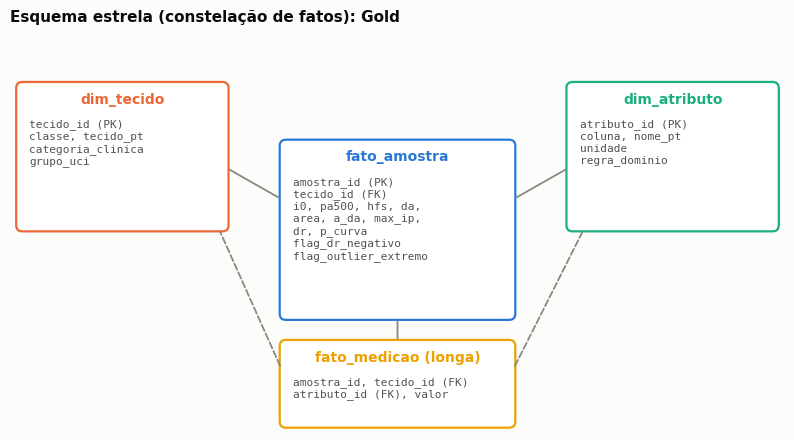

In [13]:
MERMAID_ESTRELA = """```mermaid
erDiagram
    dim_tecido ||--o{ fato_amostra : "tecido_id"
    dim_tecido ||--o{ fato_medicao : "tecido_id"
    dim_atributo ||--o{ fato_medicao : "atributo_id"
    fato_amostra ||--o{ fato_medicao : "amostra_id"
    dim_tecido { int tecido_id PK
        string classe
        string tecido_pt
        string categoria_clinica
        string grupo_uci }
    dim_atributo { int atributo_id PK
        string coluna
        string nome_pt
        string unidade
        string regra_dominio }
    fato_amostra { int amostra_id PK
        int tecido_id FK
        float i0
        float pa500
        float hfs
        float da
        float area
        float a_da
        float max_ip
        float dr
        float p_curva
        bool flag_dr_negativo
        bool flag_outlier_extremo }
    fato_medicao { int amostra_id FK
        int tecido_id FK
        int atributo_id FK
        float valor }
```"""
(CAT / "diagrama_estrela.md").write_text("# Diagrama do esquema estrela\n\n" + MERMAID_ESTRELA, encoding="utf-8")

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib.colors import LinearSegmentedColormap

# Paleta categórica (ordem fixa; cor segue a entidade). Com 6 classes usamos também forma de marcador e rótulo direto.
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
CORES = dict(zip(CLASSES, PALETA))
MARC = dict(zip(CLASSES, ["o", "s", "^", "D", "v", "P"]))
TINTA, TINTA_2, MUDO, GRADE, SUPERFICIE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
CMAP_SEQ = LinearSegmentedColormap.from_list("seq_azul", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95"])
CMAP_DIV = LinearSegmentedColormap.from_list("div_azul_vermelho", ["#2a78d6", "#f0efec", "#e34948"])

def estilo_graficos():
    plt.rcParams.update({
        "figure.dpi": 100, "savefig.dpi": 150, "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE,
        "savefig.facecolor": SUPERFICIE, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA_2, "text.color": TINTA,
        "xtick.color": MUDO, "ytick.color": MUDO, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.7,
        "axes.axisbelow": True, "legend.frameon": False, "font.size": 9.5})
estilo_graficos()

def salvar_fig(fig, nome):
    fig.savefig(EVID / nome, bbox_inches="tight")
    plt.show()

def graf_estrela(salvar=None):
    fig, ax = plt.subplots(figsize=(10, 5.2)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 5.2)
    def caixa(x, y, w, h, titulo, linhas, cor):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc="#ffffff", ec=cor, lw=1.6))
        ax.text(x + w / 2, y + h - 0.2, titulo, ha="center", va="center", fontweight="bold", color=cor, fontsize=10)
        ax.text(x + 0.15, y + h - 0.45, "\n".join(linhas), ha="left", va="top", fontsize=8, color=TINTA_2, family="monospace")
    caixa(3.5, 1.45, 3.0, 2.3, "fato_amostra", ["amostra_id (PK)", "tecido_id (FK)", "i0, pa500, hfs, da,", "area, a_da, max_ip,", "dr, p_curva", "flag_dr_negativo", "flag_outlier_extremo"], PALETA[0])
    caixa(0.1, 2.6, 2.7, 1.9, "dim_tecido", ["tecido_id (PK)", "classe, tecido_pt", "categoria_clinica", "grupo_uci"], PALETA[1])
    caixa(7.2, 2.6, 2.7, 1.9, "dim_atributo", ["atributo_id (PK)", "coluna, nome_pt", "unidade", "regra_dominio"], PALETA[2])
    caixa(3.5, 0.05, 3.0, 1.1, "fato_medicao (longa)", ["amostra_id, tecido_id (FK)", "atributo_id (FK), valor"], PALETA[3])
    for (x0, y0, x1, y1) in [(2.8, 3.4, 3.5, 3.0), (7.2, 3.4, 6.5, 3.0)]:
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-", color=MUDO, lw=1.3))
    ax.annotate("", xy=(5, 1.45), xytext=(5, 1.15), arrowprops=dict(arrowstyle="-", color=MUDO, lw=1.3))
    ax.annotate("", xy=(7.4, 2.6), xytext=(6.5, 0.8), arrowprops=dict(arrowstyle="-", color=MUDO, lw=1.3, ls="--"))
    ax.annotate("", xy=(2.7, 2.6), xytext=(3.5, 0.8), arrowprops=dict(arrowstyle="-", color=MUDO, lw=1.3, ls="--"))
    ax.set_title("Esquema estrela (constelação de fatos): Gold", loc="left")
    if salvar: salvar_fig(fig, salvar)
    return fig

_ = graf_estrela(salvar="modelo_estrela.png")
fig = _
fig.savefig(CAT / "diagrama_estrela.png", bbox_inches="tight")

## 9. Análise
A análise **lê a camada Gold** (tabelas `fato_amostra` e `dim_tecido`). Cada seção traz: método → gráfico → **discussão gerada dos números desta execução**. Resultados fracos ou inconclusivos são relatados como tal. As figuras são salvas em `evidencias/`.

**Cuidados metodológicos (amostra pequena, n ≈ 105).**
- Toda avaliação usa **validação cruzada estratificada repetida** (5 dobras × 10 repetições) e **o pré-processamento é ajustado dentro de cada dobra** (sem vazamento). Hiperparâmetros são escolhidos por **validação cruzada aninhada** (laço interno de 3 dobras).
- Atributos assimétricos são tratados com **transformação de potência de Yeo–Johnson + padronização** (dentro do *pipeline*), em modelos sensíveis à escala (kNN, regressão logística, SVM, agrupamento). Árvores e florestas usam os valores originais.
- Métrica principal: **macro-F1** (cada classe pesa igual); também acurácia e acurácia balanceada.
- Testes de hipótese usam métodos **não paramétricos** (Kruskal–Wallis; Mann–Whitney) com correção de **Benjamini–Hochberg**.

In [14]:
# ---------- CARGA DA CAMADA GOLD PARA A ANÁLISE ----------------------------------------
from itertools import combinations
from scipy import stats
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, confusion_matrix, roc_auc_score,
                             roc_curve, average_precision_score, silhouette_score, adjusted_rand_score,
                             normalized_mutual_info_score)

cols_f = ", ".join(f"f.{c}" for c in FEATURES)
base = sql(f"""
SELECT f.amostra_id, t.classe, t.tecido_pt, t.categoria_clinica, t.grupo_uci, {cols_f}, f.flag_outlier_extremo
FROM {T('fato_amostra')} f JOIN {T('dim_tecido')} t ON f.tecido_id = t.tecido_id
ORDER BY f.amostra_id""")
X = base[FEATURES].values.astype(float)
y6 = np.asarray(base["classe"], dtype=object)
yb = (base["classe"] == "car").astype(int).values
g3 = np.asarray(base["grupo_uci"], dtype=object)
N = len(base)
R = {}      # resultados numéricos da execução (alimentam discussões, README e JSON)
print(f"Base de análise: {N} amostras × {len(FEATURES)} atributos | classes: { {k: int(v) for k, v in base['classe'].value_counts().reindex(CLASSES).items()} }")
base.head()

Base de análise: 105 amostras × 9 atributos | classes: {'car': 21, 'fad': 15, 'mas': 18, 'gla': 15, 'con': 14, 'adi': 22}


,amostra_id,classe,tecido_pt,categoria_clinica,grupo_uci,i0,pa500,hfs,da,area,a_da,max_ip,dr,p_curva,flag_outlier_extremo
0,1,car,Carcinoma,Maligno,G1 carcinoma,524.794072,0.187448,0.032114,228.800228,6843.598481,29.910803,60.204880,220.737212,556.828334,False
1,2,car,Carcinoma,Maligno,G1 carcinoma,330.000000,0.226893,0.265290,121.154201,3163.239472,26.109202,69.717361,99.084964,400.225776,False
2,3,car,Carcinoma,Maligno,G1 carcinoma,551.879287,0.232478,0.063530,264.804935,11888.391827,44.894903,77.793297,253.785300,656.769449,False
3,4,car,Carcinoma,Maligno,G1 carcinoma,380.000000,0.240855,0.286234,137.640111,5402.171180,39.248524,88.758446,105.198568,493.701814,False
4,5,car,Carcinoma,Maligno,G1 carcinoma,362.831266,0.200713,0.244346,124.912559,3290.462446,26.342127,69.389389,103.866552,424.796503,False


### 9.0 Qualidade dos dados: evidências gráficas

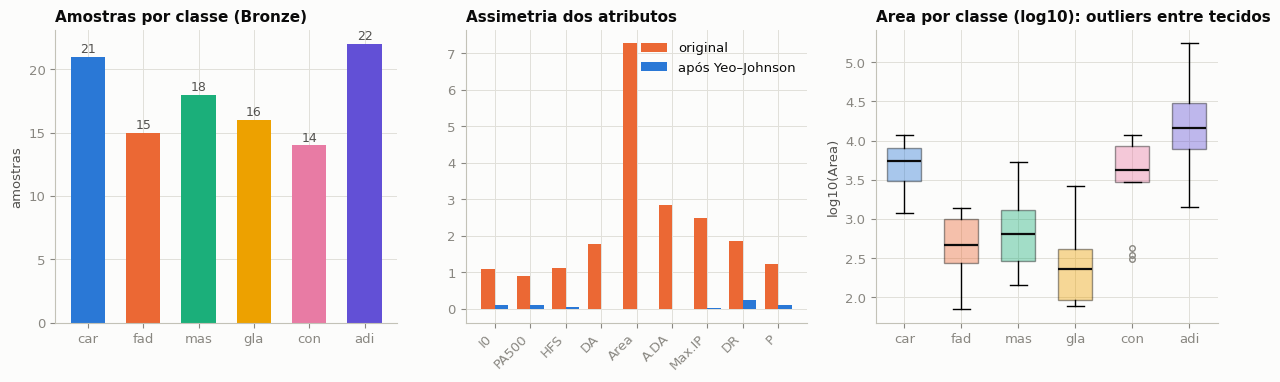

**Leitura.** A base **não tem nulos** e o rótulo é válido em todas as linhas; `A.DA = Area/DA` e `P ≥ DA` valem em 100% dos registros (consistência interna). Os achados são: **1 linha repetida** (idêntica em todos os atributos e na classe; removida na Silver, R2), **1 valor de `dr` negativo** (mantido e sinalizado, R3), **6 amostras com valor extremo dentro da própria classe** (mantidas e sinalizadas, R4) e **forte assimetria** em vários atributos (tratada com Yeo–Johnson dentro dos modelos). As classes têm de 14 a 22 amostras: **amostra pequena**, o que limita a precisão de qualquer estimativa.

In [15]:
def graf_qualidade(raw, base, salvar=None):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    vc = raw["classe"].value_counts().reindex(CLASSES)
    ax[0].bar(range(6), vc.values, color=[CORES[c] for c in CLASSES], width=.62)
    for i, v in enumerate(vc.values):
        ax[0].text(i, v + .3, str(v), ha="center", fontsize=9, color=TINTA_2)
    ax[0].set_xticks(range(6)); ax[0].set_xticklabels(CLASSES); ax[0].set_title("Amostras por classe (Bronze)"); ax[0].set_ylabel("amostras")
    sk = perfil_q.set_index("atributo")["assimetria"].reindex(FEATURES)
    pt = PowerTransformer().fit_transform(raw[FEATURES])
    sk2 = pd.Series(stats.skew(pt), index=FEATURES)
    x = np.arange(len(FEATURES)); w = .38
    ax[1].bar(x - w / 2, sk.values, w, color=PALETA[1], label="original")
    ax[1].bar(x + w / 2, sk2.values, w, color=PALETA[0], label="após Yeo–Johnson")
    ax[1].set_xticks(x); ax[1].set_xticklabels([ROTULO[c] for c in FEATURES], rotation=45, ha="right")
    ax[1].set_title("Assimetria dos atributos"); ax[1].legend()
    dados = [np.log10(raw.loc[raw["classe"] == k, "area"].values) for k in CLASSES]
    bp = ax[2].boxplot(dados, positions=range(6), widths=.6, patch_artist=True, medianprops=dict(color=TINTA, lw=1.6),
                       flierprops=dict(marker="o", markersize=4, markeredgecolor=MUDO))
    for p, k in zip(bp["boxes"], CLASSES):
        p.set_facecolor(CORES[k]); p.set_alpha(.4)
    ax[2].set_xticks(range(6)); ax[2].set_xticklabels(CLASSES); ax[2].set_title("Area por classe (log10): outliers entre tecidos"); ax[2].set_ylabel("log10(Area)")
    if salvar: salvar_fig(fig, salvar)
    return fig

_ = graf_qualidade(raw, base, salvar="qualidade_visao_geral.png")
n_dup = int(duplicatas.shape[0])
n_out = int(silver["flag_outlier_extremo"].sum())
mostrar_md(f"**Leitura.** A base **não tem nulos** e o rótulo é válido em todas as linhas; `A.DA = Area/DA` e `P ≥ DA` valem em 100% dos registros (consistência interna). "
           f"Os achados são: **{n_dup} linha repetida** (idêntica em todos os atributos e na classe; removida na Silver, R2), **1 valor de `dr` negativo** (mantido e sinalizado, R3), "
           f"**{n_out} amostras com valor extremo dentro da própria classe** (mantidas e sinalizadas, R4) e **forte assimetria** em vários atributos (tratada com Yeo–Johnson dentro dos modelos). "
           f"As classes têm de {int(raw['classe'].value_counts().min())} a {int(raw['classe'].value_counts().max())} amostras: **amostra pequena**, o que limita a precisão de qualquer estimativa.")

## P1 · Quais atributos diferenciam os tecidos e quais são redundantes?
**Método.** Para cada atributo, teste de **Kruskal–Wallis** entre as 6 classes, com tamanho de efeito **ε²** (Tomczak & Tomczak, 2014) e p ajustado por Benjamini–Hochberg. Redundância por **correlação de Spearman** (|ρ| ≥ 0,90).

In [16]:
def bh(p):
    """Ajuste de Benjamini-Hochberg (FDR)."""
    p = np.asarray(p, float); n = len(p); o = np.argsort(p)
    q = p[o] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(n); out[o] = np.minimum(q, 1)
    return out

def forca_eps(e):
    return "muito forte" if e >= .64 else "forte" if e >= .36 else "relativamente forte" if e >= .16 else "moderado" if e >= .04 else "fraco"

def kruskal_atributos(df):
    n = len(df); linhas = []
    for c in FEATURES:
        H, p = stats.kruskal(*[g[c].values for _, g in df.groupby("classe")])
        linhas.append({"atributo": c, "H": H, "p": p, "epsilon2": H * (n + 1) / (n ** 2 - 1)})
    kw = pd.DataFrame(linhas)
    kw["p_adj"] = bh(kw["p"].values)
    kw["efeito"] = kw["epsilon2"].map(forca_eps)
    return kw.sort_values("epsilon2", ascending=False).reset_index(drop=True)

def pares_redundantes(df, lim=.90):
    corr = df[FEATURES].corr(method="spearman")
    pares = [(a, b, corr.loc[a, b]) for a, b in combinations(FEATURES, 2) if abs(corr.loc[a, b]) >= lim]
    return corr, sorted(pares, key=lambda t: -abs(t[2]))

kw = kruskal_atributos(base)
corr_sp, pares_red = pares_redundantes(base)
medianas = base.groupby("classe")[FEATURES].median().reindex(CLASSES)
R["kw"] = kw.to_dict("records"); R["pares_redundantes"] = [(a, b, float(r)) for a, b, r in pares_red]
salvar_tabela(kw, "gold_p1_kruskal_atributos")
display(kw.round(4))
display(medianas.round(3))

,atributo,H,p,epsilon2,p_adj,efeito
0,p_curva,85.7699,0.0000,0.8247,0.0000,muito forte
1,i0,82.7502,0.0000,0.7957,0.0000,muito forte
2,da,81.0826,0.0000,0.7796,0.0000,muito forte
3,max_ip,78.2782,0.0000,0.7527,0.0000,muito forte
4,area,75.0145,0.0000,0.7213,0.0000,muito forte
5,dr,69.5078,0.0000,0.6683,0.0000,muito forte
6,a_da,67.6438,0.0000,0.6504,0.0000,muito forte
7,pa500,56.3380,0.0000,0.5417,0.0000,forte
8,hfs,17.2041,0.0041,0.1654,0.0041,relativamente forte


,i0,pa500,hfs,da,area,a_da,max_ip,dr,p_curva
classe,,,,,,,,,
car,389.873,0.213,0.195,172.371,5541.256,31.301,69.389,153.173,477.548
fad,245.000,0.091,0.082,58.244,465.087,10.660,20.086,52.793,267.517
mas,267.635,0.126,0.088,68.682,668.526,11.533,34.039,59.405,294.226
gla,197.000,0.124,0.080,33.461,197.013,5.953,25.921,13.963,215.373
con,1328.166,0.076,0.058,381.042,4186.211,14.768,70.105,372.053,1121.189
adi,1974.559,0.070,0.119,370.058,14426.639,44.593,164.632,286.922,2068.051


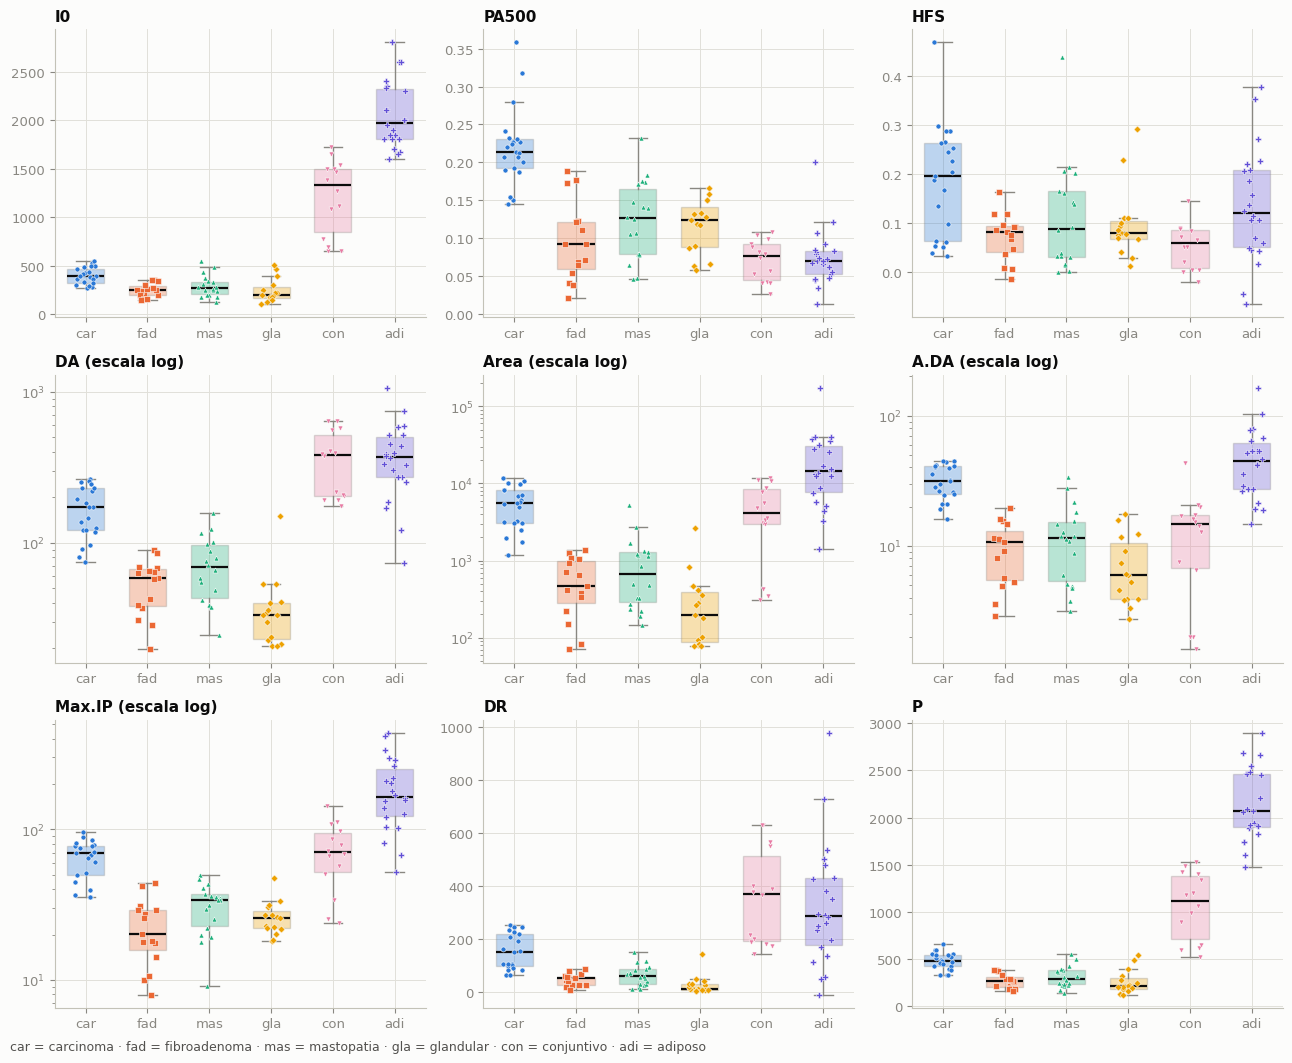

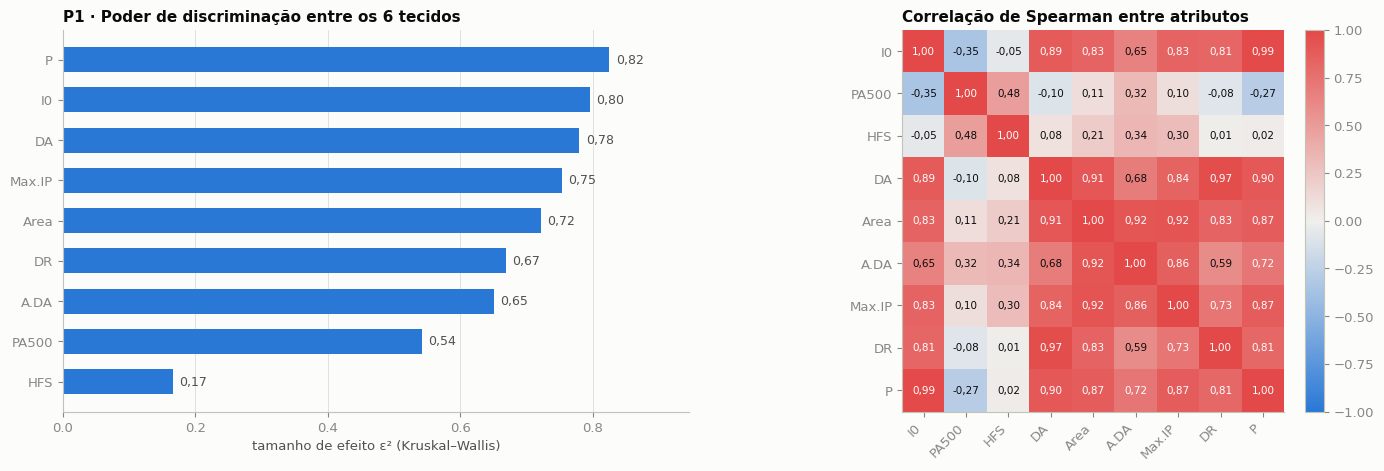

In [17]:
def graf_boxplots(df, salvar=None):
    fig, axs = plt.subplots(3, 3, figsize=(13, 10.5))
    rng = np.random.default_rng(SEED)
    for ax, c in zip(axs.ravel(), FEATURES):
        dados = [df.loc[df["classe"] == k, c].values for k in CLASSES]
        bp = ax.boxplot(dados, positions=range(6), widths=.6, patch_artist=True, showfliers=False, medianprops=dict(color=TINTA, lw=1.6),
                        whiskerprops=dict(color=MUDO), capprops=dict(color=MUDO), boxprops=dict(edgecolor=MUDO))
        for patch, k in zip(bp["boxes"], CLASSES):
            patch.set_facecolor(CORES[k]); patch.set_alpha(.30)
        for i, k in enumerate(CLASSES):
            v = dados[i]
            ax.scatter(i + rng.uniform(-.18, .18, len(v)), v, s=13, color=CORES[k], marker=MARC[k], edgecolor=SUPERFICIE, linewidth=.4, zorder=3)
        suf = ""
        if df[c].min() > 0 and df[c].skew() > 1.5:
            ax.set_yscale("log"); suf = " (escala log)"
        ax.set_xticks(range(6)); ax.set_xticklabels(CLASSES); ax.set_title(ROTULO[c] + suf)
    fig.text(0.01, -0.005, "car = carcinoma · fad = fibroadenoma · mas = mastopatia · gla = glandular · con = conjuntivo · adi = adiposo", color=TINTA_2, fontsize=9)
    fig.tight_layout()
    if salvar: salvar_fig(fig, salvar)
    return fig

def graf_efeito_corr(kw, corr, salvar=None):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
    k = kw.sort_values("epsilon2")
    ax[0].barh([ROTULO[a] for a in k["atributo"]], k["epsilon2"], color=PALETA[0], height=.62)
    for i, v in enumerate(k["epsilon2"]):
        ax[0].text(v + .01, i, br(v, 2), va="center", fontsize=9, color=TINTA_2)
    ax[0].set_xlim(0, max(.75, k["epsilon2"].max() + .12)); ax[0].set_xlabel("tamanho de efeito ε² (Kruskal–Wallis)")
    ax[0].set_title("P1 · Poder de discriminação entre os 6 tecidos")
    ax[0].grid(axis="y", visible=False)
    nomes = [ROTULO[c] for c in FEATURES]
    im = ax[1].imshow(corr.values, cmap=CMAP_DIV, vmin=-1, vmax=1)
    ax[1].set_xticks(range(9)); ax[1].set_xticklabels(nomes, rotation=45, ha="right"); ax[1].set_yticks(range(9)); ax[1].set_yticklabels(nomes)
    for i in range(9):
        for j in range(9):
            ax[1].text(j, i, br(corr.values[i, j], 2), ha="center", va="center", fontsize=7.5, color=TINTA if abs(corr.values[i, j]) < .7 else "#ffffff")
    ax[1].grid(False); ax[1].set_title("Correlação de Spearman entre atributos")
    fig.colorbar(im, ax=ax[1], fraction=.046, pad=.03)
    fig.tight_layout()
    if salvar: salvar_fig(fig, salvar)
    return fig

_ = graf_boxplots(base, salvar="p1_boxplots_atributos.png")
_ = graf_efeito_corr(kw, corr_sp, salvar="p1_efeito_correlacao.png")

In [18]:
def disc_p1(kw, pares_red, medianas, n):
    sig = kw[kw["p_adj"] < .05]
    top = kw.head(3)
    L = ["### Discussão P1 — atributos que diferenciam os tecidos"]
    top_txt = ", ".join(f"**{ROTULO[r.atributo]}** (ε² = {br(r.epsilon2, 2)}, {r.efeito})" for r in top.itertuples())
    L.append(f"- **Poder de discriminação:** {len(sig)} dos {len(kw)} atributos diferem entre as 6 classes (Kruskal–Wallis, p ajustado < 0,05). "
             f"Os mais discriminantes são {top_txt}. O menos discriminante é **{ROTULO[kw.iloc[-1]['atributo']]}** (ε² = {br(kw.iloc[-1]['epsilon2'], 2)}, {kw.iloc[-1]['efeito']}).")
    maior = {c: medianas[c].idxmax() for c in FEATURES}
    conta = pd.Series(maior).value_counts()
    L.append("- **Perfil por tecido:** " + "; ".join(f"**{NOME_TECIDO[k]}** tem a maior mediana em {int(v)} dos 9 atributos" for k, v in conta.items()) +
             ". Isso mostra que a escala das medidas separa sobretudo tecidos de natureza muito diferente; para tecidos parecidos é preciso olhar a combinação de atributos (P2).")
    if pares_red:
        txt = ", ".join(f"{ROTULO[a]}–{ROTULO[b]} (ρ = {br(r, 2)})" for a, b, r in pares_red[:5])
        L.append(f"- **Redundância:** {len(pares_red)} pares de atributos têm |ρ| ≥ 0,90, por exemplo {txt}. Muitos atributos derivam do mesmo espectro (distâncias, área e comprimento da curva), "
                 "portanto carregam **informação sobreposta**: modelos lineares sofrem com multicolinearidade e é possível reduzir o número de variáveis coletadas (testado em P5).")
    else:
        L.append("- **Redundância:** nenhum par com |ρ| ≥ 0,90.")
    L.append(f"- **Ressalva:** com n = {n} e classes de 14 a 22 amostras, testes de significância têm pouco poder e p-valores pequenos não garantem generalização; os ε² são estimativas imprecisas.")
    return "\n".join(L)

mostrar_md(disc_p1(kw, pares_red, medianas, N))

### Discussão P1 — atributos que diferenciam os tecidos
- **Poder de discriminação:** 9 dos 9 atributos diferem entre as 6 classes (Kruskal–Wallis, p ajustado < 0,05). Os mais discriminantes são **P** (ε² = 0,82, muito forte), **I0** (ε² = 0,80, muito forte), **DA** (ε² = 0,78, muito forte). O menos discriminante é **HFS** (ε² = 0,17, relativamente forte).
- **Perfil por tecido:** **Adiposo** tem a maior mediana em 5 dos 9 atributos; **Carcinoma** tem a maior mediana em 2 dos 9 atributos; **Conjuntivo** tem a maior mediana em 2 dos 9 atributos. Isso mostra que a escala das medidas separa sobretudo tecidos de natureza muito diferente; para tecidos parecidos é preciso olhar a combinação de atributos (P2).
- **Redundância:** 5 pares de atributos têm |ρ| ≥ 0,90, por exemplo I0–P (ρ = 0,99), DA–DR (ρ = 0,97), Area–Max.IP (ρ = 0,92), Area–A.DA (ρ = 0,92), DA–Area (ρ = 0,91). Muitos atributos derivam do mesmo espectro (distâncias, área e comprimento da curva), portanto carregam **informação sobreposta**: modelos lineares sofrem com multicolinearidade e é possível reduzir o número de variáveis coletadas (testado em P5).
- **Ressalva:** com n = 105 e classes de 14 a 22 amostras, testes de significância têm pouco poder e p-valores pequenos não garantem generalização; os ε² são estimativas imprecisas.

## P2 · Os seis tecidos são separáveis? Desempenho e pares confundidos
**Método.** (i) **Separabilidade univariada por par de classes:** Mann–Whitney em cada atributo para os 15 pares de tecidos (135 testes, FDR de Benjamini–Hochberg); conta-se em quantos atributos o par se separa. (ii) **Classificação supervisionada** de 6 classes com baseline e 5 modelos, avaliada por validação cruzada estratificada repetida (5×10) com ajuste de hiperparâmetros aninhado.

In [19]:
def separabilidade_pares(df, alpha=.05):
    linhas = []
    for a, b in combinations(CLASSES, 2):
        for c in FEATURES:
            p = stats.mannwhitneyu(df.loc[df["classe"] == a, c], df.loc[df["classe"] == b, c], alternative="two-sided").pvalue
            linhas.append({"a": a, "b": b, "atributo": c, "p": p})
    d = pd.DataFrame(linhas); d["p_adj"] = bh(d["p"].values); d["separa"] = d["p_adj"] < alpha
    mat = pd.DataFrame(0, index=CLASSES, columns=CLASSES)
    for r in d.itertuples():
        if r.separa:
            mat.loc[r.a, r.b] += 1; mat.loc[r.b, r.a] += 1
    return d, mat

pares_df, mat_sep = separabilidade_pares(base)
R["mat_sep"] = mat_sep.to_dict()
display(mat_sep)

,car,fad,mas,gla,con,adi
car,0,9,9,8,7,8
fad,9,0,1,2,6,7
mas,9,1,0,3,7,8
gla,8,2,3,0,7,8
con,7,6,7,7,0,6
adi,8,7,8,8,6,0


In [20]:
# ---------- MODELOS E VALIDAÇÃO CRUZADA --------------------------------------------------
def pre():
    return PowerTransformer(method="yeo-johnson", standardize=True)

def cv_interno():
    return StratifiedKFold(3, shuffle=True, random_state=SEED)

def modelos_multiclasse():
    return {
        "Baseline (classe majoritária)": DummyClassifier(strategy="most_frequent"),
        "Árvore (profundidade 3)": DecisionTreeClassifier(max_depth=3, random_state=SEED),
        "kNN": GridSearchCV(Pipeline([("pre", pre()), ("m", KNeighborsClassifier())]), {"m__n_neighbors": [3, 5, 7, 9]}, cv=cv_interno(), scoring="f1_macro"),
        "Regressão logística": GridSearchCV(Pipeline([("pre", pre()), ("m", LogisticRegression(max_iter=5000))]), {"m__C": [.1, 1, 10, 100]}, cv=cv_interno(), scoring="f1_macro"),
        "SVM (RBF)": GridSearchCV(Pipeline([("pre", pre()), ("m", SVC())]), {"m__C": [1, 10, 100], "m__gamma": ["scale", .01, .1]}, cv=cv_interno(), scoring="f1_macro"),
        "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
    }

def avaliar_cv_multi(modelo, X, y, n_splits=N_SPLITS, n_repeats=N_REPEATS, seed=SEED):
    """CV estratificada repetida. Devolve métricas por dobra e as predições fora da amostra (repetições × n)."""
    linhas, oof = [], np.empty((n_repeats, len(y)), dtype=object)
    for r in range(n_repeats):
        for k, (tr, te) in enumerate(StratifiedKFold(n_splits, shuffle=True, random_state=seed + r).split(X, y)):
            pred = clone(modelo).fit(X[tr], y[tr]).predict(X[te])
            oof[r, te] = pred
            linhas.append({"rep": r, "dobra": k, "macro_f1": f1_score(y[te], pred, average="macro"),
                           "acuracia": accuracy_score(y[te], pred), "acuracia_balanceada": balanced_accuracy_score(y[te], pred)})
    return pd.DataFrame(linhas), oof

with etapa("P2 classificação"):
    res_cv, oof_modelos, folds = [], {}, {}
    for nome, mod in modelos_multiclasse().items():
        f, oof = avaliar_cv_multi(mod, X, y6)
        folds[nome], oof_modelos[nome] = f, oof
        res_cv.append({"modelo": nome, "macro_f1": f["macro_f1"].mean(), "macro_f1_dp": f["macro_f1"].std(),
                       "acuracia": f["acuracia"].mean(), "acuracia_dp": f["acuracia"].std(),
                       "acuracia_balanceada": f["acuracia_balanceada"].mean()})
res_cv = pd.DataFrame(res_cv).sort_values("macro_f1", ascending=False).reset_index(drop=True)
melhor = res_cv[~res_cv["modelo"].str.startswith("Baseline")].iloc[0]["modelo"]
f1_base = float(res_cv.loc[res_cv["modelo"].str.startswith("Baseline"), "macro_f1"].iloc[0])
R["p2_modelos"] = res_cv.to_dict("records"); R["p2_melhor"] = melhor
salvar_tabela(res_cv, "gold_p2_modelos_cv")
res_cv.round(4)

,modelo,macro_f1,macro_f1_dp,acuracia,acuracia_dp,acuracia_balanceada
0,Regressão logística,0.6772,0.0992,0.7038,0.0899,0.6918
1,Random Forest,0.6610,0.0978,0.6933,0.0861,0.6769
2,SVM (RBF),0.6609,0.0814,0.6914,0.0753,0.6758
3,kNN,0.6020,0.1044,0.6390,0.0991,0.6255
4,Árvore (profundidade 3),0.4815,0.0616,0.5857,0.0661,0.5571
5,Baseline (classe majoritária),0.0576,0.0053,0.2095,0.0236,0.1667


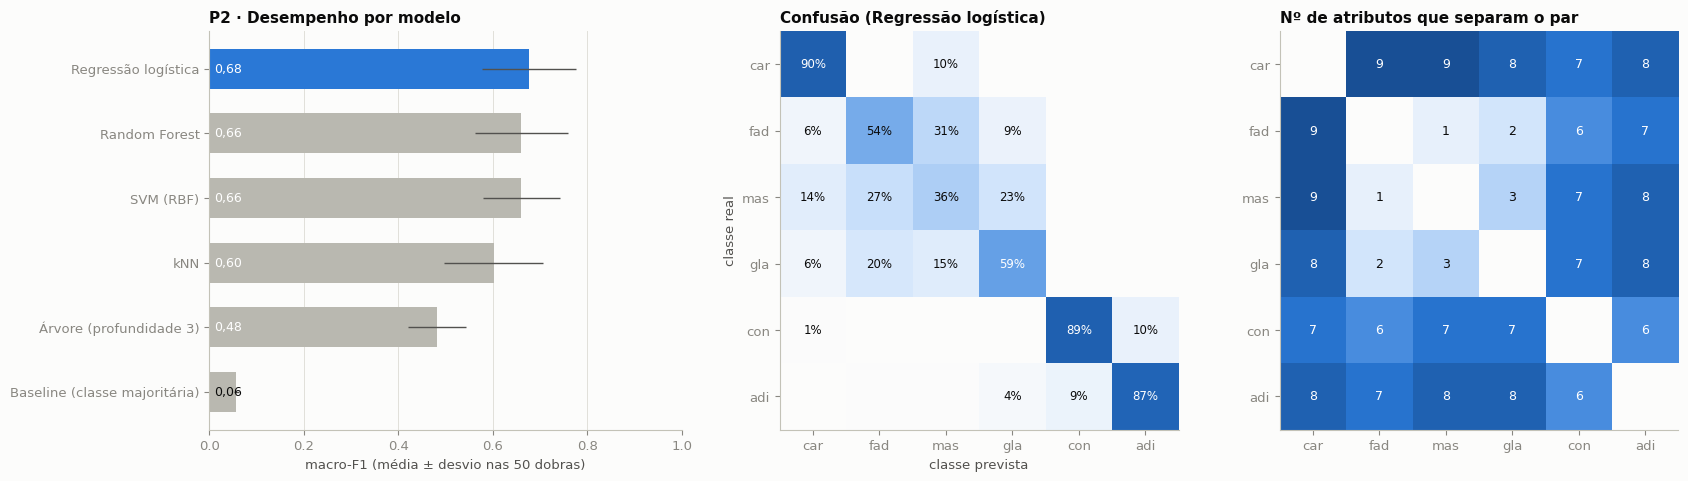

,recall (sensibilidade)
car,0.900
fad,0.540
mas,0.361
gla,0.587
con,0.893
adi,0.868


In [21]:
def matriz_confusao(oof, y, labels=CLASSES):
    cm = sum(confusion_matrix(y, oof[r].astype(str), labels=labels) for r in range(oof.shape[0])) / oof.shape[0]
    return pd.DataFrame(cm, index=labels, columns=labels)

cm = matriz_confusao(oof_modelos[melhor], y6)
cm_norm = cm.div(cm.sum(axis=1), axis=0)
recall = pd.Series(np.diag(cm_norm.values), index=CLASSES)
# Acurácia ao nível dos 3 grupos (a partir das mesmas predições)
mapa_g = np.vectorize(lambda c: GRUPO_UCI[c])
acc_g3 = float(np.mean([(mapa_g(oof_modelos[melhor][r].astype(str)) == g3).mean() for r in range(N_REPEATS)]))
acc_6 = float(res_cv.loc[res_cv["modelo"] == melhor, "acuracia"].iloc[0])
# Pares mais confundidos
conf_pares = sorted(((a, b, (cm.loc[a, b] + cm.loc[b, a]) / (cm.loc[a].sum() + cm.loc[b].sum())) for a, b in combinations(CLASSES, 2)), key=lambda t: -t[2])
R.update({"p2_recall": recall.to_dict(), "p2_acc_g3": acc_g3, "p2_conf_pares": [(a, b, float(v)) for a, b, v in conf_pares[:5]]})
salvar_tabela(cm.round(4).reset_index().rename(columns={"index": "classe_real"}), "gold_p2_matriz_confusao")

def graf_p2(res_cv, cm, cm_norm, mat_sep, melhor, salvar=None):
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.9), gridspec_kw={"width_ratios": [1.05, 1, .9]})
    r = res_cv.sort_values("macro_f1")
    cores = [PALETA[0] if m == melhor else "#b9b8b0" for m in r["modelo"]]
    ax[0].barh(r["modelo"], r["macro_f1"], xerr=r["macro_f1_dp"], color=cores, height=.62, error_kw=dict(ecolor=TINTA_2, lw=1))
    for i, v in enumerate(r["macro_f1"]):
        ax[0].text(.01, i, br(v, 2), va="center", fontsize=9, color="#ffffff" if v > .15 else TINTA)
    ax[0].set_xlim(0, 1.0); ax[0].set_xlabel("macro-F1 (média ± desvio nas 50 dobras)"); ax[0].set_title("P2 · Desempenho por modelo"); ax[0].grid(axis="y", visible=False)
    im = ax[1].imshow(cm_norm.values, cmap=CMAP_SEQ, vmin=0, vmax=1)
    ax[1].set_xticks(range(6)); ax[1].set_xticklabels(CLASSES); ax[1].set_yticks(range(6)); ax[1].set_yticklabels(CLASSES)
    for i in range(6):
        for j in range(6):
            v = cm_norm.values[i, j]
            ax[1].text(j, i, f"{100 * v:.0f}%" if v >= .005 else "", ha="center", va="center", fontsize=8.5, color="#ffffff" if v > .55 else TINTA)
    ax[1].set_xlabel("classe prevista"); ax[1].set_ylabel("classe real"); ax[1].grid(False); ax[1].set_title(f"Confusão ({melhor})")
    im2 = ax[2].imshow(mat_sep.values, cmap=CMAP_SEQ, vmin=0, vmax=9)
    ax[2].set_xticks(range(6)); ax[2].set_xticklabels(CLASSES); ax[2].set_yticks(range(6)); ax[2].set_yticklabels(CLASSES)
    for i in range(6):
        for j in range(6):
            if i != j:
                ax[2].text(j, i, str(int(mat_sep.values[i, j])), ha="center", va="center", fontsize=9, color="#ffffff" if mat_sep.values[i, j] > 5 else TINTA)
    ax[2].grid(False); ax[2].set_title("Nº de atributos que separam o par")
    fig.tight_layout()
    if salvar: salvar_fig(fig, salvar)
    return fig

_ = graf_p2(res_cv, cm, cm_norm, mat_sep, melhor, salvar="p2_modelos_confusao.png")
pd.DataFrame({"recall (sensibilidade)": recall.round(3)})

In [22]:
def disc_p2(res_cv, melhor, f1_base, recall, acc_g3, acc_6, conf_pares, mat_sep):
    r = res_cv[res_cv["modelo"] == melhor].iloc[0]
    L = ["### Discussão P2 — separabilidade dos seis tecidos"]
    resp = "sim" if r.macro_f1 >= .8 else "**parcialmente**: bem para alguns tecidos e mal para outros (ver abaixo)" if r.macro_f1 >= .5 else "pouco"
    L.append(f"- **Resposta:** {resp}. O melhor modelo foi **{melhor}**, com **macro-F1 = {br(r.macro_f1, 2)} ± {br(r.macro_f1_dp, 2)}**, acurácia {pct(r.acuracia)} e acurácia balanceada {pct(r.acuracia_balanceada)} "
             f"(validação cruzada 5×10 com ajuste aninhado). O baseline (sempre a classe majoritária) fica em macro-F1 = {br(f1_base, 2)}; o ganho é de {br(r.macro_f1 - f1_base, 2)} pontos de F1.")
    pior, melhor_c = recall.idxmin(), recall.idxmax()
    L.append(f"- **Por classe:** maior sensibilidade em **{NOME_TECIDO[melhor_c]}** ({pct(recall[melhor_c], 0)}) e menor em **{NOME_TECIDO[pior]}** ({pct(recall[pior], 0)}). "
             f"A sensibilidade para **carcinoma** é {pct(recall['car'], 0)} no problema de 6 classes.")
    top = conf_pares[:3]
    L.append("- **Pares confundidos:** " + "; ".join(f"{NOME_TECIDO[a]} × {NOME_TECIDO[b]} ({pct(v, 0)} das amostras do par trocadas)" for a, b, v in top) + ".")
    sem = [(a, b) for a, b in combinations(CLASSES, 2) if mat_sep.loc[a, b] == 0]
    if sem:
        L.append("- **Convergência com os testes univariados:** nenhum atributo, isoladamente, separa " + ", ".join(f"{NOME_TECIDO[a]}–{NOME_TECIDO[b]}" for a, b in sem) + " (p ajustado ≥ 0,05); são pares que a classificação também troca.")
    L.append(f"- **Agrupamento em 3 grupos:** agrupando as predições em G1 (carcinoma), G2 (fibroadenoma+mastopatia+glandular) e G3 (conjuntivo+adiposo), a acurácia sobe de {pct(acc_6)} (6 classes) para **{pct(acc_g3)}**. "
             "Ou seja, boa parte do erro ocorre **dentro dos grupos**, o que sustenta o agrupamento da literatura como nível de decisão mais realista.")
    L.append("- **Limites:** n pequeno, média ± desvio entre dobras (que **não são independentes**) subestima a incerteza, e comparar 5 modelos na mesma validação favorece levemente o melhor (viés de seleção). "
             "A base não traz identificador de paciente: se houver várias amostras do mesmo paciente, a validação cruzada pode estar **otimista** (vazamento entre dobras).")
    return "\n".join(L)

mostrar_md(disc_p2(res_cv, melhor, f1_base, recall, acc_g3, acc_6, conf_pares, mat_sep))

### Discussão P2 — separabilidade dos seis tecidos
- **Resposta:** **parcialmente**: bem para alguns tecidos e mal para outros (ver abaixo). O melhor modelo foi **Regressão logística**, com **macro-F1 = 0,68 ± 0,10**, acurácia 70,4% e acurácia balanceada 69,2% (validação cruzada 5×10 com ajuste aninhado). O baseline (sempre a classe majoritária) fica em macro-F1 = 0,06; o ganho é de 0,62 pontos de F1.
- **Por classe:** maior sensibilidade em **Carcinoma** (90%) e menor em **Mastopatia** (36%). A sensibilidade para **carcinoma** é 90% no problema de 6 classes.
- **Pares confundidos:** Fibroadenoma × Mastopatia (28% das amostras do par trocadas); Mastopatia × Glandular (19% das amostras do par trocadas); Fibroadenoma × Glandular (15% das amostras do par trocadas).
- **Agrupamento em 3 grupos:** agrupando as predições em G1 (carcinoma), G2 (fibroadenoma+mastopatia+glandular) e G3 (conjuntivo+adiposo), a acurácia sobe de 70,4% (6 classes) para **92,8%**. Ou seja, boa parte do erro ocorre **dentro dos grupos**, o que sustenta o agrupamento da literatura como nível de decisão mais realista.
- **Limites:** n pequeno, média ± desvio entre dobras (que **não são independentes**) subestima a incerteza, e comparar 5 modelos na mesma validação favorece levemente o melhor (viés de seleção). A base não traz identificador de paciente: se houver várias amostras do mesmo paciente, a validação cruzada pode estar **otimista** (vazamento entre dobras).

## P3 · Triagem de carcinoma × não carcinoma com sensibilidade ≥ 90%
**Método.** Problema binário (carcinoma = 21 amostras, 20%). Dois modelos com pesos de classe balanceados (regressão logística e Random Forest), probabilidades **fora da amostra** em validação cruzada 5×10. Escolhe-se o modelo de maior AUC e, nas probabilidades médias, o **maior limiar com sensibilidade ≥ `SENSIBILIDADE_ALVO`** (um falso negativo, carcinoma não sinalizado, é o erro mais custoso). Intervalos de confiança por **bootstrap**. Como a prevalência da base (20%) é artificial, o valor preditivo é recalculado para prevalências hipotéticas pelo teorema de Bayes.

In [23]:
def modelos_bin():
    return {
        "Regressão logística": GridSearchCV(Pipeline([("pre", pre()), ("m", LogisticRegression(max_iter=5000, class_weight="balanced"))]),
                                            {"m__C": [.1, 1, 10, 100]}, cv=cv_interno(), scoring="roc_auc"),
        "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", random_state=SEED, n_jobs=1),
    }

def avaliar_cv_bin(modelo, X, y, n_splits=N_SPLITS, n_repeats=N_REPEATS, seed=SEED):
    prob = np.zeros((n_repeats, len(y)))
    for r in range(n_repeats):
        for tr, te in StratifiedKFold(n_splits, shuffle=True, random_state=seed + r).split(X, y):
            prob[r, te] = clone(modelo).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
    return prob

def metricas_limiar(y, p, lim):
    pred = p >= lim
    tp, fn = int((pred & (y == 1)).sum()), int((~pred & (y == 1)).sum())
    fp, tn = int((pred & (y == 0)).sum()), int((~pred & (y == 0)).sum())
    return {"sens": tp / (tp + fn), "espec": tn / (tn + fp), "vpp": tp / (tp + fp) if tp + fp else np.nan,
            "vpn": tn / (tn + fn) if tn + fn else np.nan, "tp": tp, "fn": fn, "fp": fp, "tn": tn}

def vpp_prevalencia(sens, espec, prev):
    return sens * prev / (sens * prev + (1 - espec) * (1 - prev))

with etapa("P3 triagem"):
    probs, auc_bin = {}, []
    for nome, mod in modelos_bin().items():
        pr = avaliar_cv_bin(mod, X, yb)
        probs[nome] = pr
        aucs = [roc_auc_score(yb, pr[r]) for r in range(pr.shape[0])]
        aps = [average_precision_score(yb, pr[r]) for r in range(pr.shape[0])]
        auc_bin.append({"modelo": nome, "auc": np.mean(aucs), "auc_dp": np.std(aucs, ddof=1), "ap": np.mean(aps), "prevalencia": yb.mean()})
auc_bin = pd.DataFrame(auc_bin).sort_values("auc", ascending=False).reset_index(drop=True)
melhor_bin = auc_bin.iloc[0]["modelo"]
pm = probs[melhor_bin].mean(axis=0)               # probabilidade média fora da amostra (todas as repetições)
fpr, tpr, thr = roc_curve(yb, pm)
limiar = float(thr[int(np.where(tpr >= SENSIBILIDADE_ALVO)[0][0])])
op = metricas_limiar(yb, pm, limiar)
auc_pm = roc_auc_score(yb, pm)

rng = np.random.default_rng(SEED); b_auc, b_sens, b_esp = [], [], []
for _ in range(N_BOOT):
    i = rng.integers(0, N, N)
    if yb[i].min() == yb[i].max():
        continue
    m = metricas_limiar(yb[i], pm[i], limiar)
    b_auc.append(roc_auc_score(yb[i], pm[i])); b_sens.append(m["sens"]); b_esp.append(m["espec"])
ic = lambda v: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5)))
R["p3"] = {"melhor": melhor_bin, "limiar": limiar, "auc": float(auc_pm), "auc_ic": ic(b_auc), **{k: float(v) for k, v in op.items()},
           "sens_ic": ic(b_sens), "espec_ic": ic(b_esp)}
# Linha de base: melhor atributo isolado (AUC univariada; escolha feita sobre os dados, portanto levemente otimista)
auc_uni = pd.DataFrame({"atributo": FEATURES, "auc": [max(roc_auc_score(yb, base[c]), 1 - roc_auc_score(yb, base[c])) for c in FEATURES]}).sort_values("auc", ascending=False)
# Falsos positivos por classe de não carcinoma
fp_classe = (pd.DataFrame({"classe": y6, "sinalizado": pm >= limiar}).query("classe != 'car'").groupby("classe")["sinalizado"].mean().reindex([c for c in CLASSES if c != "car"]))
vpp_tab = pd.DataFrame([{"prevalência": pct(p, 0), "VPP": pct(vpp_prevalencia(op["sens"], op["espec"], p), 1),
                         "VPN": pct((op["espec"] * (1 - p)) / (op["espec"] * (1 - p) + (1 - op["sens"]) * p), 1)} for p in PREVALENCIAS])
R["p3"]["vpp_prev"] = {str(p): float(vpp_prevalencia(op["sens"], op["espec"], p)) for p in PREVALENCIAS}
R["p3"]["fp_classe"] = fp_classe.to_dict(); R["p3"]["auc_uni_top"] = auc_uni.head(3).to_dict("records")
salvar_tabela(auc_bin, "gold_p3_modelos_auc")
salvar_tabela(pd.DataFrame({"amostra_id": base["amostra_id"], "classe": y6, "prob_carcinoma": pm, "sinalizado": pm >= limiar}), "gold_p3_predicoes_oof")
display(auc_bin.round(4))
display(pd.DataFrame([{"limiar": round(limiar, 4), **{k: round(v, 4) if isinstance(v, float) else v for k, v in op.items()}}]))
display(vpp_tab)
display(auc_uni.head(4).round(3))

,modelo,auc,auc_dp,ap,prevalencia
0,Random Forest,0.9731,0.0085,0.8966,0.2
1,Regressão logística,0.9661,0.0083,0.8442,0.2


,limiar,sens,espec,vpp,vpn,tp,fn,fp,tn
0,0.3735,0.9524,0.9524,0.8333,0.9877,20,1,4,80


,prevalência,VPP,VPN
0,1%,"16,8%","99,9%"
1,5%,"51,3%","99,7%"
2,20%,"83,3%","98,8%"


,atributo,auc
1,pa500,0.970
5,a_da,0.789
2,hfs,0.723
4,area,0.692


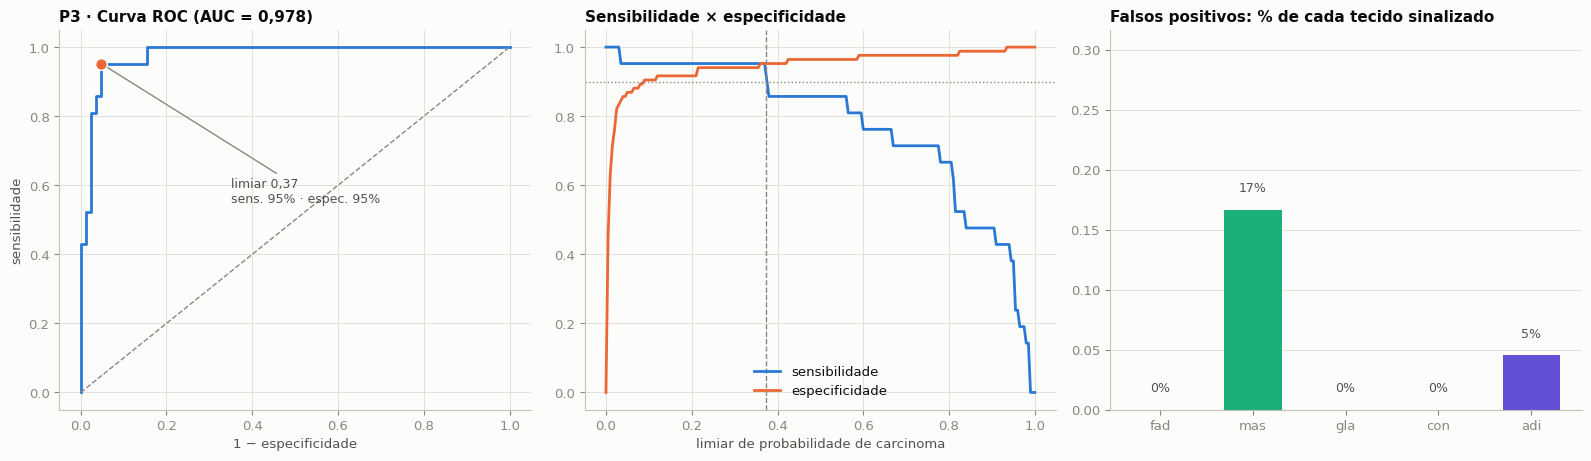

### Discussão P3 — triagem de carcinoma
- **Discriminação:** o melhor modelo (Random Forest) atinge **AUC = 0,978** (IC95% bootstrap 0,95–1,00; média das repetições 0,973 ± 0,009), precisão média = 0,90 (referência de acaso = prevalência, 0,20). Para comparação, o melhor atributo isolado (**PA500**) tem AUC = 0,970: **um único atributo praticamente iguala o modelo multivariado** para esta pergunta (a escolha do melhor atributo foi feita sobre os próprios dados, portanto é levemente otimista).
- **Ponto de operação:** com limiar 0,37, a sensibilidade é **95,2%** (IC95% 83%–100%; 1 de 21 carcinomas não sinalizados) e a especificidade **95,2%** (IC95% 90%–99%; 4 falsos positivos). A meta de sensibilidade foi atingida. O limiar foi escolhido nas mesmas probabilidades em que é avaliado, portanto a sensibilidade/especificidade reais tendem a ser um pouco **menores**.
- **Onde estão os falsos positivos:** o tecido mais sinalizado indevidamente é **Mastopatia** (17% das amostras); os demais ficam entre 0% e 5%.
- **Valor preditivo depende da prevalência:** com essa sensibilidade/especificidade, o VPP seria **17%** a 1% de prevalência, **51%** a 5% de prevalência, **83%** a 20% de prevalência. Em um cenário de rastreamento (prevalência baixa) a maioria dos alertas seria falso; o teste serve como **apoio à decisão para amostras já suspeitas**, não como rastreamento populacional.
- **Limites:** 21 casos de carcinoma geram intervalos largos; amostras ex vivo; sem validação externa; custo relativo FN:FP não informado (a meta de 90% é uma premissa do aluno).

In [24]:
def graf_p3(fpr, tpr, thr, pm, yb, limiar, op, fp_classe, auc_pm, salvar=None):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.7))
    ax[0].plot(fpr, tpr, color=PALETA[0], lw=2); ax[0].plot([0, 1], [0, 1], color=MUDO, lw=1, ls="--")
    ax[0].scatter([1 - op["espec"]], [op["sens"]], s=70, color=PALETA[1], zorder=5, edgecolor=SUPERFICIE)
    ax[0].annotate(f"limiar {br(limiar, 2)}\nsens. {pct(op['sens'], 0)} · espec. {pct(op['espec'], 0)}", (1 - op["espec"], op["sens"]),
                   xytext=(.35, .55), fontsize=9, color=TINTA_2, arrowprops=dict(arrowstyle="-", color=MUDO))
    ax[0].set_xlabel("1 − especificidade"); ax[0].set_ylabel("sensibilidade"); ax[0].set_title(f"P3 · Curva ROC (AUC = {br(auc_pm, 3)})")
    ts = np.linspace(0, 1, 201)
    sens = [metricas_limiar(yb, pm, t)["sens"] for t in ts]; esp = [metricas_limiar(yb, pm, t)["espec"] for t in ts]
    ax[1].plot(ts, sens, color=PALETA[0], lw=2, label="sensibilidade"); ax[1].plot(ts, esp, color=PALETA[1], lw=2, label="especificidade")
    ax[1].axvline(limiar, color=MUDO, lw=1, ls="--"); ax[1].axhline(SENSIBILIDADE_ALVO, color=MUDO, lw=1, ls=":")
    ax[1].set_xlabel("limiar de probabilidade de carcinoma"); ax[1].set_title("Sensibilidade × especificidade"); ax[1].legend(loc="lower center")
    ax[2].bar(range(len(fp_classe)), fp_classe.values, color=[CORES[c] for c in fp_classe.index], width=.62)
    for i, v in enumerate(fp_classe.values):
        ax[2].text(i, v + .015, pct(v, 0), ha="center", fontsize=9, color=TINTA_2)
    ax[2].set_xticks(range(len(fp_classe))); ax[2].set_xticklabels(fp_classe.index); ax[2].set_ylim(0, min(1.05, max(fp_classe.max() + .15, .3)))
    ax[2].set_title("Falsos positivos: % de cada tecido sinalizado"); ax[2].grid(axis="x", visible=False)
    fig.tight_layout()
    if salvar: salvar_fig(fig, salvar)
    return fig

_ = graf_p3(fpr, tpr, thr, pm, yb, limiar, op, fp_classe, auc_pm, salvar="p3_triagem_carcinoma.png")

def disc_p3(P, auc_bin, auc_uni, fp_classe):
    L = ["### Discussão P3 — triagem de carcinoma"]
    a = auc_bin.iloc[0]
    L.append(f"- **Discriminação:** o melhor modelo ({P['melhor']}) atinge **AUC = {br(P['auc'], 3)}** (IC95% bootstrap {br(P['auc_ic'][0], 2)}–{br(P['auc_ic'][1], 2)}; média das repetições {br(a.auc, 3)} ± {br(a.auc_dp, 3)}), "
             f"precisão média = {br(a.ap, 2)} (referência de acaso = prevalência, {br(a.prevalencia, 2)}). Para comparação, o melhor atributo isolado (**{ROTULO[auc_uni.iloc[0]['atributo']]}**) tem AUC = {br(auc_uni.iloc[0]['auc'], 3)}"
             + (": **um único atributo praticamente iguala o modelo multivariado** para esta pergunta (a escolha do melhor atributo foi feita sobre os próprios dados, portanto é levemente otimista)." if auc_uni.iloc[0]['auc'] >= P['auc'] - .02 else "."))
    atingiu = P["sens"] >= SENSIBILIDADE_ALVO
    L.append(f"- **Ponto de operação:** com limiar {br(P['limiar'], 2)}, a sensibilidade é **{pct(P['sens'])}** (IC95% {pct(P['sens_ic'][0], 0)}–{pct(P['sens_ic'][1], 0)}; {int(P['fn'])} de {int(P['tp'] + P['fn'])} carcinomas não sinalizados) "
             f"e a especificidade **{pct(P['espec'])}** (IC95% {pct(P['espec_ic'][0], 0)}–{pct(P['espec_ic'][1], 0)}; {int(P['fp'])} falsos positivos). "
             + ("A meta de sensibilidade foi atingida." if atingiu else "A meta de sensibilidade **não** foi atingida.") +
             " O limiar foi escolhido nas mesmas probabilidades em que é avaliado, portanto a sensibilidade/especificidade reais tendem a ser um pouco **menores**.")
    pior = fp_classe.idxmax()
    L.append(f"- **Onde estão os falsos positivos:** o tecido mais sinalizado indevidamente é **{NOME_TECIDO[pior]}** ({pct(fp_classe[pior], 0)} das amostras); os demais ficam entre {pct(fp_classe.drop(pior).min(), 0)} e {pct(fp_classe.drop(pior).max(), 0)}.")
    vp = P["vpp_prev"]
    L.append("- **Valor preditivo depende da prevalência:** com essa sensibilidade/especificidade, o VPP seria " +
             ", ".join(f"**{pct(v, 0)}** a {pct(float(k), 0)} de prevalência" for k, v in vp.items()) +
             ". Em um cenário de rastreamento (prevalência baixa) a maioria dos alertas seria falso; o teste serve como **apoio à decisão para amostras já suspeitas**, não como rastreamento populacional.")
    L.append("- **Limites:** 21 casos de carcinoma geram intervalos largos; amostras ex vivo; sem validação externa; custo relativo FN:FP não informado (a meta de 90% é uma premissa do aluno).")
    return "\n".join(L)

mostrar_md(disc_p3(R["p3"], auc_bin, auc_uni, fp_classe))

## P4 · Existem grupos naturais? Eles coincidem com os tecidos?
**Método.** Aprendizado **não supervisionado** (os rótulos não entram no ajuste): K-Means (k de 2 a 8) e agrupamento hierárquico de Ward sobre os atributos com Yeo–Johnson + padronização. Qualidade interna pelo **silhouette**; concordância com os rótulos por **ARI** (índice de Rand ajustado) e **NMI**. Estabilidade por 5 sementes.

In [25]:
with etapa("P4 agrupamento"):
    Zc = PowerTransformer(method="yeo-johnson", standardize=True).fit_transform(X)
    linhas, rot_km = [], {}
    for k in range(2, 9):
        lab = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(Zc)
        wd = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Zc)
        rot_km[k] = lab
        linhas.append({"k": k, "silhouette_kmeans": silhouette_score(Zc, lab), "silhouette_ward": silhouette_score(Zc, wd),
                       "ARI_classes_kmeans": adjusted_rand_score(y6, lab), "NMI_classes_kmeans": normalized_mutual_info_score(y6, lab),
                       "ARI_grupos3_kmeans": adjusted_rand_score(g3, lab), "ARI_classes_ward": adjusted_rand_score(y6, wd)})
    agr = pd.DataFrame(linhas)
    k_best = int(agr.loc[agr["silhouette_kmeans"].idxmax(), "k"])
    def estab_km(k):
        base_lab = rot_km[k]
        return float(np.mean([adjusted_rand_score(base_lab, KMeans(n_clusters=k, n_init=20, random_state=s).fit_predict(Zc)) for s in (1, 7, 21, 99)]))
    estab_kbest, estab_k6 = estab_km(k_best), estab_km(6)
    pca = PCA(n_components=2, random_state=SEED).fit(Zc); Zp = pca.transform(Zc)
R["p4"] = {"k_best": k_best, "tabela": agr.to_dict("records"), "estab_kbest": estab_kbest, "estab_k6": estab_k6,
           "var_pca2": float(pca.explained_variance_ratio_.sum())}
salvar_tabela(agr, "gold_p4_agrupamento_metricas")
salvar_tabela(pd.DataFrame({"amostra_id": base["amostra_id"], "classe": y6, "cluster_k6": rot_km[6], "cluster_kbest": rot_km[k_best]}), "gold_p4_clusters")
display(agr.round(3))
print(f"k com maior silhouette (K-Means): {k_best} | estabilidade (ARI entre sementes): k={k_best}: {estab_kbest:.3f}; k=6: {estab_k6:.3f}")
print("Contingência classe × cluster (K-Means, k = 6):")
display(pd.crosstab(pd.Series(y6, name="classe").map(NOME_TECIDO), pd.Series(rot_km[6], name="cluster")))
if k_best != 6:
    print(f"Contingência classe × cluster (K-Means, k = {k_best}):")
    display(pd.crosstab(pd.Series(y6, name="classe").map(NOME_TECIDO), pd.Series(rot_km[k_best], name="cluster")))

,k,silhouette_kmeans,silhouette_ward,ARI_classes_kmeans,NMI_classes_kmeans,ARI_grupos3_kmeans,ARI_classes_ward
0,2,0.393,0.372,0.235,0.362,0.517,0.231
1,3,0.359,0.353,0.415,0.564,0.735,0.374
2,4,0.337,0.318,0.434,0.523,0.534,0.430
3,5,0.328,0.307,0.439,0.556,0.431,0.399
4,6,0.317,0.304,0.419,0.553,0.393,0.418
5,7,0.321,0.309,0.380,0.548,0.356,0.404
6,8,0.327,0.321,0.420,0.588,0.418,0.420


k com maior silhouette (K-Means): 2 | estabilidade (ARI entre sementes): k=2: 1.000; k=6: 0.983
Contingência classe × cluster (K-Means, k = 6):


cluster,0,1,2,3,4,5
classe,,,,,,
Adiposo,16,0,6,0,0,0
Carcinoma,0,0,0,0,4,17
Conjuntivo,1,0,10,3,0,0
Fibroadenoma,0,3,0,6,6,0
Glandular,0,11,0,2,2,0
Mastopatia,0,6,0,3,7,2


Contingência classe × cluster (K-Means, k = 2):


cluster,0,1
classe,,
Adiposo,0,22
Carcinoma,3,18
Conjuntivo,3,11
Fibroadenoma,15,0
Glandular,14,1
Mastopatia,16,2


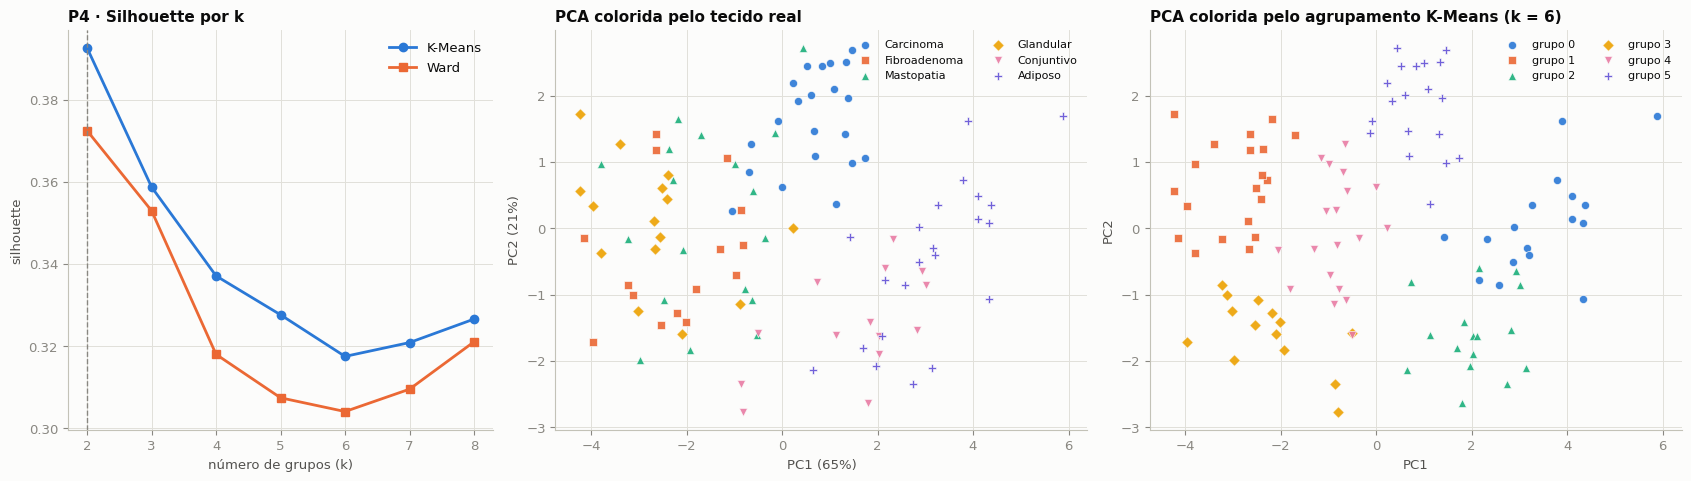

### Discussão P4 — grupos naturais
- **Número de grupos:** o silhouette do K-Means é máximo em **k = 2** (0,393 → *estrutura fraca*, escala de Kaufman & Rousseeuw); em k = 6 (o número de tecidos) cai para 0,317 (*estrutura fraca*).
- **Concordância com os tecidos:** com k = 6, ARI = **0,42** e NMI = 0,55 contra os 6 tecidos (ARI = 1 seria concordância perfeita; ≈ 0 seria acaso); contra os 3 grupos da literatura, o ARI do K-Means com k = 3 é **0,73**. Os grupos recuperam apenas parcialmente os tecidos: a estrutura natural é mais **grosseira** (poucos blocos) que a classificação em 6 tipos.
- **Estabilidade:** ARI entre sementes = 1,00 (k = 2) e 0,98 (k = 6), isto é, o resultado do K-Means é estável com `n_init = 20`.
- **Agrupamento em 3 blocos:** com k = 3 o K-Means concorda mais com os 3 grupos da literatura (ARI = 0,73) do que com os 6 tecidos (ARI = 0,42); isso é **evidência não supervisionada a favor do nível de 3 grupos** como resolução natural dos dados.
- **Leitura visual:** as duas primeiras componentes principais explicam 85% da variância; sobreposições na PCA entre tecidos próximos explicam por que o agrupamento não supervisionado não os separa, o que é coerente com os pares confundidos em P2.
- **Limite:** silhouette baixo não prova que não existam subtipos reais, apenas que a geometria dos atributos não os destaca com esse método e esse número de amostras.

In [26]:
def graf_p4(agr, Zp, pca, y6, lab6, k_best, salvar=None):
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.9), gridspec_kw={"width_ratios": [.8, 1, 1]})
    ax[0].plot(agr["k"], agr["silhouette_kmeans"], color=PALETA[0], lw=2, marker="o", ms=6, label="K-Means")
    ax[0].plot(agr["k"], agr["silhouette_ward"], color=PALETA[1], lw=2, marker="s", ms=6, label="Ward")
    ax[0].axvline(k_best, color=MUDO, ls="--", lw=1); ax[0].set_xlabel("número de grupos (k)"); ax[0].set_ylabel("silhouette"); ax[0].set_title("P4 · Silhouette por k"); ax[0].legend()
    for k in CLASSES:
        m = y6 == k
        ax[1].scatter(Zp[m, 0], Zp[m, 1], s=34, color=CORES[k], marker=MARC[k], edgecolor=SUPERFICIE, linewidth=.5, label=NOME_TECIDO[k], alpha=.9)
    ax[1].set_xlabel(f"PC1 ({pct(pca.explained_variance_ratio_[0], 0)})"); ax[1].set_ylabel(f"PC2 ({pct(pca.explained_variance_ratio_[1], 0)})")
    ax[1].set_title("PCA colorida pelo tecido real"); ax[1].legend(fontsize=8, ncol=2, loc="best")
    for c in range(6):
        m = lab6 == c
        ax[2].scatter(Zp[m, 0], Zp[m, 1], s=34, color=PALETA[c], marker=["o", "s", "^", "D", "v", "P"][c], edgecolor=SUPERFICIE, linewidth=.5, label=f"grupo {c}", alpha=.9)
    ax[2].set_xlabel("PC1"); ax[2].set_ylabel("PC2"); ax[2].set_title("PCA colorida pelo agrupamento K-Means (k = 6)"); ax[2].legend(fontsize=8, ncol=2)
    fig.tight_layout()
    if salvar: salvar_fig(fig, salvar)
    return fig

_ = graf_p4(agr, Zp, pca, y6, rot_km[6], k_best, salvar="p4_agrupamento_pca.png")

def disc_p4(agr, k_best, estab_kbest, estab_k6, var2):
    rb, r6 = agr[agr["k"] == k_best].iloc[0], agr[agr["k"] == 6].iloc[0]
    def faixa(s):
        return "estrutura forte" if s > .70 else "estrutura razoável" if s > .50 else "estrutura fraca" if s > .25 else "sem estrutura substancial"
    L = ["### Discussão P4 — grupos naturais"]
    L.append(f"- **Número de grupos:** o silhouette do K-Means é máximo em **k = {k_best}** ({br(rb.silhouette_kmeans, 3)} → *{faixa(rb.silhouette_kmeans)}*, escala de Kaufman & Rousseeuw); "
             f"em k = 6 (o número de tecidos) cai para {br(r6.silhouette_kmeans, 3)} (*{faixa(r6.silhouette_kmeans)}*).")
    L.append(f"- **Concordância com os tecidos:** com k = 6, ARI = **{br(r6.ARI_classes_kmeans, 2)}** e NMI = {br(r6.NMI_classes_kmeans, 2)} contra os 6 tecidos "
             f"(ARI = 1 seria concordância perfeita; ≈ 0 seria acaso); contra os 3 grupos da literatura, o ARI do K-Means com k = 3 é **{br(agr[agr['k'] == 3].iloc[0].ARI_grupos3_kmeans, 2)}**. "
             + ("Os grupos recuperam apenas parcialmente os tecidos: a estrutura natural é mais **grosseira** (poucos blocos) que a classificação em 6 tipos." if r6.ARI_classes_kmeans < .6 else "Os grupos recuperam bem os tecidos."))
    L.append(f"- **Estabilidade:** ARI entre sementes = {br(estab_kbest, 2)} (k = {k_best}) e {br(estab_k6, 2)} (k = 6), isto é, o resultado do K-Means é {'estável' if min(estab_kbest, estab_k6) > .9 else 'sensível à inicialização'} com `n_init = 20`.")
    a3 = agr[agr["k"] == 3].iloc[0]
    if a3.ARI_grupos3_kmeans > r6.ARI_classes_kmeans:
        L.append(f"- **Agrupamento em 3 blocos:** com k = 3 o K-Means concorda mais com os 3 grupos da literatura (ARI = {br(a3.ARI_grupos3_kmeans, 2)}) do que com os 6 tecidos (ARI = {br(r6.ARI_classes_kmeans, 2)}); "
                 "isso é **evidência não supervisionada a favor do nível de 3 grupos** como resolução natural dos dados.")
    L.append(f"- **Leitura visual:** as duas primeiras componentes principais explicam {pct(var2, 0)} da variância; sobreposições na PCA entre tecidos próximos explicam por que o agrupamento não supervisionado não os separa, o que é coerente com os pares confundidos em P2.")
    L.append("- **Limite:** silhouette baixo não prova que não existam subtipos reais, apenas que a geometria dos atributos não os destaca com esse método e esse número de amostras.")
    return "\n".join(L)

mostrar_md(disc_p4(agr, k_best, estab_kbest, estab_k6, R["p4"]["var_pca2"]))

## P5 · Quantas variáveis bastam? Existe uma regra interpretável?
**Método.** (i) **Importância por permutação** (Random Forest) medida nas amostras de teste de cada dobra (balanced accuracy). (ii) **Curva de macro-F1 × número de variáveis:** em cada dobra, as variáveis são ranqueadas **só com o treino** e avalia-se o top-*m* (m = 1…9) em Random Forest e SVM, sem vazamento. (iii) **Árvore de decisão rasa** (profundidade 1–5) e suas regras.

In [27]:
with etapa("P5 parcimônia"):
    imp, curva, sel = [], [], []
    mod_curva = {"Random Forest": RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=1),
                 "SVM (RBF)": Pipeline([("pre", pre()), ("m", SVC(C=10))])}
    for r in range(N_REPEATS_P5):
        for tr, te in StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED + 100 + r).split(X, y6):
            rf = RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=1).fit(X[tr], y6[tr])
            pi = permutation_importance(rf, X[te], y6[te], n_repeats=10, random_state=SEED, scoring="balanced_accuracy")
            imp.append(pi.importances_mean)
            ordem = np.argsort(-rf.feature_importances_)
            sel.append(ordem)
            for m in range(1, len(FEATURES) + 1):
                cols = ordem[:m]
                for nome, mod in mod_curva.items():
                    pred = clone(mod).fit(X[tr][:, cols], y6[tr]).predict(X[te][:, cols])
                    curva.append({"m": m, "modelo": nome, "macro_f1": f1_score(y6[te], pred, average="macro")})
imp = np.array(imp)
imp_df = pd.DataFrame({"atributo": FEATURES, "importancia_media": imp.mean(0), "desvio": imp.std(0, ddof=1)}).sort_values("importancia_media", ascending=False).reset_index(drop=True)
curva_df = pd.DataFrame(curva).groupby(["modelo", "m"])["macro_f1"].agg(["mean", "std"]).reset_index()
f1_cheio = curva_df[curva_df["m"] == len(FEATURES)].set_index("modelo")["mean"]
modelo_ref = curva_df.groupby("modelo")["mean"].max().idxmax()
c_ref = curva_df[curva_df["modelo"] == modelo_ref].set_index("m")["mean"]
m_min = int(next(m for m in range(1, 10) if c_ref[m] >= c_ref.max() - TOL_PARSIMONIA))
freq = pd.Series(np.concatenate([o[:m_min] for o in sel])).map(dict(enumerate(FEATURES))).value_counts() / len(sel)
freq_df = freq.reindex(FEATURES).fillna(0).sort_values(ascending=False).rename("frequência no top-m").reset_index().rename(columns={"index": "atributo"})
# Árvores rasas
prof = []
for d in [1, 2, 3, 4, 5]:
    f, _ = avaliar_cv_multi(DecisionTreeClassifier(max_depth=d, random_state=SEED), X, y6, n_repeats=5)
    prof.append({"profundidade": d, "macro_f1": f["macro_f1"].mean(), "macro_f1_dp": f["macro_f1"].std(), "acuracia": f["acuracia"].mean()})
prof = pd.DataFrame(prof)
arvore = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X, y6)
regras = export_text(arvore, feature_names=[ROTULO[c] for c in FEATURES], decimals=2)
R["p5"] = {"imp": imp_df.to_dict("records"), "m_min": m_min, "modelo_ref": modelo_ref, "f1_max": float(c_ref.max()), "f1_m_min": float(c_ref[m_min]),
           "freq": freq_df.to_dict("records"), "arvore": prof.to_dict("records")}
salvar_tabela(imp_df, "gold_p5_importancia_permutacao")
salvar_tabela(curva_df, "gold_p5_curva_variaveis")
salvar_tabela(prof, "gold_p5_arvores_rasas")
display(imp_df.round(4)); display(curva_df.pivot(index="m", columns="modelo", values="mean").round(3)); display(prof.round(3))
print("Regras da árvore (profundidade 3, ajustada em todos os dados apenas para ilustração):")
print(regras)

,atributo,importancia_media,desvio
0,i0,0.0618,0.0472
1,pa500,0.0462,0.0371
2,da,0.0461,0.0549
3,max_ip,0.0378,0.0468
4,p_curva,0.0304,0.0291
5,dr,0.0236,0.0525
6,area,0.0131,0.0349
7,hfs,0.0029,0.0379
8,a_da,0.0022,0.0282


modelo,Random Forest,SVM (RBF)
m,,
1,0.422,0.517
2,0.542,0.527
3,0.560,0.577
4,0.602,0.609
5,0.640,0.651
6,0.662,0.682
7,0.646,0.681
8,0.667,0.689
9,0.662,0.662


,profundidade,macro_f1,macro_f1_dp,acuracia
0,1,0.217,0.015,0.390
1,2,0.350,0.039,0.488
2,3,0.479,0.065,0.581
3,4,0.535,0.075,0.600
4,5,0.598,0.094,0.629


Regras da árvore (profundidade 3, ajustada em todos os dados apenas para ilustração):
|--- P <= 1563.84
|   |--- I0 <= 600.62
|   |   |--- Area <= 1710.45
|   |   |   |--- class: mas
|   |   |--- Area >  1710.45
|   |   |   |--- class: car
|   |--- I0 >  600.62
|   |   |--- Area <= 12253.91
|   |   |   |--- class: con
|   |   |--- Area >  12253.91
|   |   |   |--- class: adi
|--- P >  1563.84
|   |--- class: adi



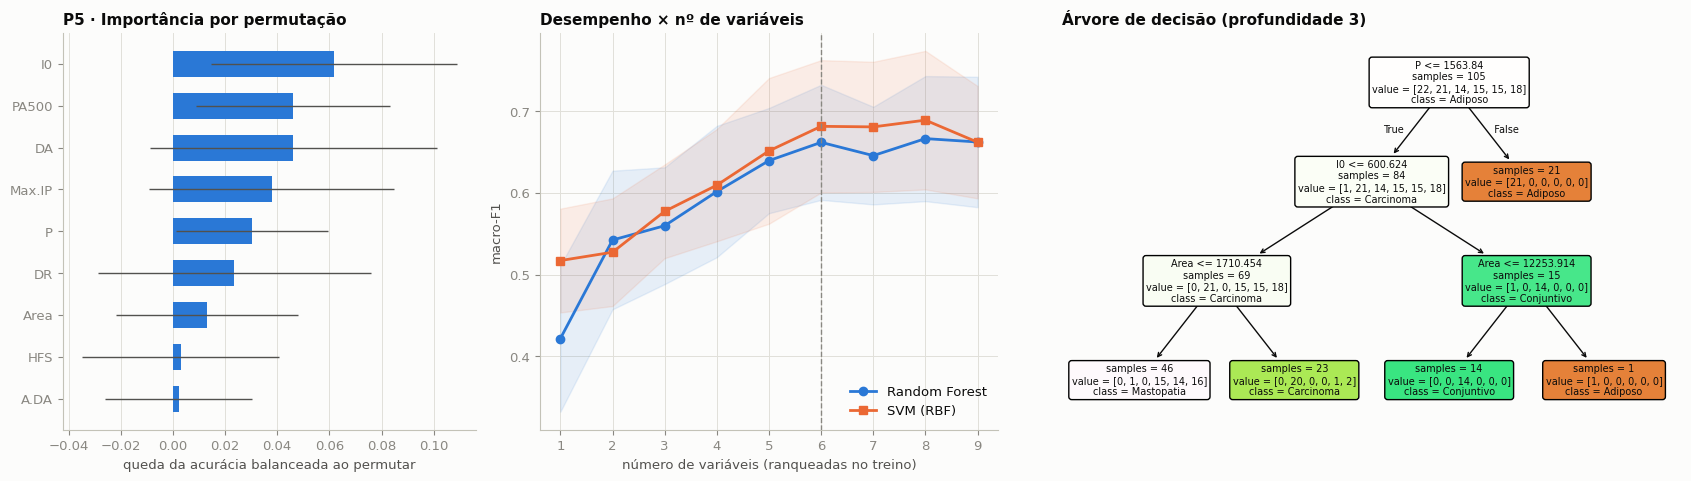

### Discussão P5 — parcimônia e interpretabilidade
- **Variáveis mais importantes (permutação):** **I0** (0,062), **PA500** (0,046), **DA** (0,046). A importância é dividida entre variáveis correlacionadas (P1), por isso valores individuais subestimam o grupo.
- **Quantas bastam (6 classes):** com SVM (RBF), o macro-F1 máximo (0,69) ocorre com 8 variáveis; **6** já ficam a no máximo 0,02 do máximo (macro-F1 = 0,68; com todas as 9: 0,66). Variáveis mais frequentes no top-6 entre as dobras: I0 (100%), PA500 (100%), DA (100%), P (100%), Max.IP (93%), A.DA (80%). A redução é **pequena**: a curva sobe de forma gradual, ou seja, para separar 6 tecidos quase todas as medidas contribuem. Para coletar menos medidas, a seleção deve ser **reavaliada em dados independentes**.
- **Incerteza:** os desvios entre dobras da importância por permutação são comparáveis às médias (ver barras de erro); o ranking individual é **incerto**, sobretudo entre variáveis correlacionadas.
- **Regra interpretável:** uma árvore de profundidade 3 alcança macro-F1 = **0,48** (acurácia 58%) em validação cruzada, contra 0,68 do melhor modelo (Regressão logística). A melhor profundidade testada foi 5 (macro-F1 0,60). A diferença para o modelo completo é o preço da transparência: relevante; a regra simples serve para explicar, não para decidir sozinha.
- **Limite:** árvores são instáveis em amostras pequenas (outra amostra pode gerar outras regras); as regras impressas acima ilustram a lógica, não são limiares clínicos.

In [28]:
def graf_p5(imp_df, curva_df, m_min, arvore, salvar=None):
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.9), gridspec_kw={"width_ratios": [.9, 1, 1.35]})
    k = imp_df.sort_values("importancia_media")
    ax[0].barh([ROTULO[a] for a in k["atributo"]], k["importancia_media"], xerr=k["desvio"], color=PALETA[0], height=.62, error_kw=dict(ecolor=TINTA_2, lw=1))
    ax[0].set_xlabel("queda da acurácia balanceada ao permutar"); ax[0].set_title("P5 · Importância por permutação"); ax[0].grid(axis="y", visible=False)
    for nome, cor, mk in [("Random Forest", PALETA[0], "o"), ("SVM (RBF)", PALETA[1], "s")]:
        c = curva_df[curva_df["modelo"] == nome]
        ax[1].plot(c["m"], c["mean"], color=cor, lw=2, marker=mk, ms=6, label=nome)
        ax[1].fill_between(c["m"], c["mean"] - c["std"], c["mean"] + c["std"], color=cor, alpha=.10)
    ax[1].axvline(m_min, color=MUDO, ls="--", lw=1); ax[1].set_xlabel("número de variáveis (ranqueadas no treino)"); ax[1].set_ylabel("macro-F1")
    ax[1].set_title("Desempenho × nº de variáveis"); ax[1].legend(loc="lower right"); ax[1].set_xticks(range(1, 10))
    plot_tree(arvore, feature_names=[ROTULO[c] for c in FEATURES], class_names=[NOME_TECIDO[c] for c in arvore.classes_], filled=True, rounded=True, impurity=False,
              proportion=False, fontsize=7, ax=ax[2])
    ax[2].set_title("Árvore de decisão (profundidade 3)")
    fig.tight_layout()
    if salvar: salvar_fig(fig, salvar)
    return fig

_ = graf_p5(imp_df, curva_df, m_min, arvore, salvar="p5_parcimonia_arvore.png")

def disc_p5(imp_df, freq_df, m_min, modelo_ref, c_ref, prof, f1_melhor, nome_melhor):
    L = ["### Discussão P5 — parcimônia e interpretabilidade"]
    top = imp_df.head(3)
    L.append("- **Variáveis mais importantes (permutação):** " + ", ".join(f"**{ROTULO[r.atributo]}** ({br(r.importancia_media, 3)})" for r in top.itertuples()) +
             ". A importância é dividida entre variáveis correlacionadas (P1), por isso valores individuais subestimam o grupo.")
    sel = ", ".join(f"{ROTULO[r.atributo]} ({pct(r._2, 0)})" for r in freq_df.head(m_min).itertuples())
    L.append(f"- **Quantas bastam (6 classes):** com {modelo_ref}, o macro-F1 máximo ({br(c_ref.max(), 2)}) ocorre com {int(c_ref.idxmax())} variáveis; **{m_min}** já ficam a no máximo {br(TOL_PARSIMONIA, 2)} do máximo "
             f"(macro-F1 = {br(c_ref[m_min], 2)}; com todas as 9: {br(c_ref[9], 2)}). Variáveis mais frequentes no top-{m_min} entre as dobras: {sel}. "
             + ("A redução é **pequena**: a curva sobe de forma gradual, ou seja, para separar 6 tecidos quase todas as medidas contribuem. " if m_min >= 6 else "Poucas variáveis bastam. ")
             + "Para coletar menos medidas, a seleção deve ser **reavaliada em dados independentes**.")
    L.append("- **Incerteza:** os desvios entre dobras da importância por permutação são comparáveis às médias (ver barras de erro); o ranking individual é **incerto**, sobretudo entre variáveis correlacionadas.")
    p3 = prof[prof["profundidade"] == 3].iloc[0]
    pbest = prof.loc[prof["macro_f1"].idxmax()]
    L.append(f"- **Regra interpretável:** uma árvore de profundidade 3 alcança macro-F1 = **{br(p3.macro_f1, 2)}** (acurácia {pct(p3.acuracia, 0)}) em validação cruzada, contra {br(f1_melhor, 2)} do melhor modelo ({nome_melhor}). "
             f"A melhor profundidade testada foi {int(pbest.profundidade)} (macro-F1 {br(pbest.macro_f1, 2)}). A diferença para o modelo completo é o preço da transparência: "
             + ("pequena, a regra é uma alternativa aceitável." if f1_melhor - p3.macro_f1 < .08 else "relevante; a regra simples serve para explicar, não para decidir sozinha."))
    L.append("- **Limite:** árvores são instáveis em amostras pequenas (outra amostra pode gerar outras regras); as regras impressas acima ilustram a lógica, não são limiares clínicos.")
    return "\n".join(L)

f1_melhor = float(res_cv.loc[res_cv["modelo"] == melhor, "macro_f1"].iloc[0])
mostrar_md(disc_p5(imp_df, freq_df, m_min, modelo_ref, c_ref, prof, f1_melhor, melhor))

## Robustez: o que muda se a linha repetida for mantida?

In [29]:
with etapa("Robustez"):
    s_all, _, _ = silver_transform(bronze, remover_duplicatas=False)
    s_dedup, _, _ = silver_transform(bronze, remover_duplicatas=True)
    mod_rob = dict(modelos_multiclasse())[melhor]
    saida = []
    for rotulo_c, s in [("linha repetida mantida", s_all), ("linha repetida removida", s_dedup)]:
        f, _ = avaliar_cv_multi(mod_rob, s[FEATURES].values, np.asarray(s["classe"], dtype=object), n_repeats=3)
        saida.append({"cenário": rotulo_c, "amostras": len(s), "macro_f1": f["macro_f1"].mean(), "acuracia": f["acuracia"].mean()})
rob = pd.DataFrame(saida)
rob.to_csv(TAB / "robustez_duplicata.csv", index=False)
display(rob.round(4))
dif = float(rob.iloc[0]["macro_f1"] - rob.iloc[1]["macro_f1"])
R["robustez"] = {"dif_macro_f1": dif}
mostrar_md(f"**Leitura.** Manter a linha repetida muda o macro-F1 do modelo escolhido em **{br(dif, 3)}** ({'otimista: a cópia cai no treino e no teste' if dif > 0 else 'efeito desprezível ou negativo'}). "
           "A remoção (R2) é a decisão conservadora: o efeito é pequeno aqui porque há uma única linha repetida em 106, mas em bases maiores esse vazamento pode inflar bastante os resultados.")

,cenário,amostras,macro_f1,acuracia
0,linha repetida mantida,106,0.6820,0.7110
1,linha repetida removida,105,0.6676,0.6952


**Leitura.** Manter a linha repetida muda o macro-F1 do modelo escolhido em **0,014** (otimista: a cópia cai no treino e no teste). A remoção (R2) é a decisão conservadora: o efeito é pequeno aqui porque há uma única linha repetida em 106, mas em bases maiores esse vazamento pode inflar bastante os resultados.

## Discussão geral, viabilidade e decisão

In [30]:
def disc_geral(res_cv, melhor, P, acc_g3, k_best, agr, m_min, tempos):
    r = res_cv[res_cv["modelo"] == melhor].iloc[0]
    esp = P["espec"]
    qual = "promissora" if esp >= .8 else "moderada" if esp >= .5 else "fraca"
    L = ["### Discussão geral — o que os resultados dizem sobre o problema"]
    L.append(f"- **Técnica:** as medidas de impedância carregam informação: {melhor} chega a macro-F1 = {br(r.macro_f1, 2)} em 6 classes e a {pct(acc_g3, 0)} de acurácia no nível de 3 grupos. "
             f"O agrupamento não supervisionado, porém, só enxerga estrutura grosseira (k = {k_best}), então a separação fina entre tecidos parecidos depende de **rótulos e de modelos supervisionados**.")
    L.append(f"- **Triagem de carcinoma:** a relação sensibilidade × especificidade é **{qual}**: com sensibilidade de {pct(P['sens'], 0)} (IC95% {pct(P['sens_ic'][0], 0)}–{pct(P['sens_ic'][1], 0)}) a especificidade é {pct(esp, 0)}; estimativas **otimistas** (limiar escolhido nos mesmos dados, 21 casos). "
             "Isso apoia o uso como **teste complementar** em amostras suspeitas, e não como substituto da histologia.")
    L.append(f"- **Operacional:** para separar os 6 tecidos são necessárias cerca de {m_min} das 9 medidas (ganho de parcimônia pequeno); já para **carcinoma × resto**, o melhor atributo isolado ({ROTULO[P['auc_uni_top'][0]['atributo']]}) tem AUC = {br(P['auc_uni_top'][0]['auc'], 2)}, o que indica que a triagem pode exigir bem menos medidas que a classificação fina (a confirmar em dados independentes).")
    tot = sum(tempos.values())
    L.append(f"- **Viabilidade financeira (uso de recursos):** o pipeline completo (coleta, Bronze, Silver, Gold, validação cruzada e análises) levou **{br(tot, 0)} s** neste ambiente ({AMBIENTE}), "
             f"sobre {br(meta['tamanho_bytes'] / 1024, 1)} KB de dados brutos. É compatível com compute gratuito (Colab/Databricks Free Edition); o custo de operação é desprezível, e o custo real do projeto estaria na coleta das medidas.")
    L.append("- **Decisão recomendada:** seguir para uma fase 2 **somente** com (i) identificador de paciente para validação agrupada, (ii) conjunto de teste externo, (iii) calibração de probabilidades e definição do custo relativo FN:FP com especialistas clínicos.")
    return "\n".join(L)

mostrar_md(disc_geral(res_cv, melhor, R["p3"], acc_g3, k_best, agr, m_min, TEMPOS))

### Discussão geral — o que os resultados dizem sobre o problema
- **Técnica:** as medidas de impedância carregam informação: Regressão logística chega a macro-F1 = 0,68 em 6 classes e a 93% de acurácia no nível de 3 grupos. O agrupamento não supervisionado, porém, só enxerga estrutura grosseira (k = 2), então a separação fina entre tecidos parecidos depende de **rótulos e de modelos supervisionados**.
- **Triagem de carcinoma:** a relação sensibilidade × especificidade é **promissora**: com sensibilidade de 95% (IC95% 83%–100%) a especificidade é 95%; estimativas **otimistas** (limiar escolhido nos mesmos dados, 21 casos). Isso apoia o uso como **teste complementar** em amostras suspeitas, e não como substituto da histologia.
- **Operacional:** para separar os 6 tecidos são necessárias cerca de 6 das 9 medidas (ganho de parcimônia pequeno); já para **carcinoma × resto**, o melhor atributo isolado (PA500) tem AUC = 0,97, o que indica que a triagem pode exigir bem menos medidas que a classificação fina (a confirmar em dados independentes).
- **Viabilidade financeira (uso de recursos):** o pipeline completo (coleta, Bronze, Silver, Gold, validação cruzada e análises) levou **230 s** neste ambiente (colab), sobre 16,0 KB de dados brutos. É compatível com compute gratuito (Colab/Databricks Free Edition); o custo de operação é desprezível, e o custo real do projeto estaria na coleta das medidas.
- **Decisão recomendada:** seguir para uma fase 2 **somente** com (i) identificador de paciente para validação agrupada, (ii) conjunto de teste externo, (iii) calibração de probabilidades e definição do custo relativo FN:FP com especialistas clínicos.

## 10. Ética, licenciamento e LGPD (seção 4 do PDF)
- **Licença:** o conjunto é divulgado pelo UCI Machine Learning Repository sob **CC BY 4.0** (permite redistribuição e uso derivado, com atribuição). *Confirme na página de onde baixou o arquivo e registre a data na seção 2.* O repositório deve citar a fonte (Jossinet, 1996; UCI), informar o `sha256` do arquivo e pode versionar o CSV sob essa licença; se preferir não versionar, o notebook localiza o arquivo por upload.
- **Dados pessoais (Lei 13.709/2018):** a base contém **medidas físicas de amostras de tecido**, sem nome, CPF, e-mail, endereço, data ou identificador de paciente; `amostra_id` é apenas a posição da linha no arquivo. Não há quase-identificadores (idade, sexo, local). Dados de saúde são **dados pessoais sensíveis** (art. 5º, II); como aqui não há como vincular a medida a uma pessoa, o risco de reidentificação é considerado muito baixo, mas **não se tenta cruzar a base com outras fontes**. Nenhuma anonimização adicional foi necessária.
- **Dados corporativos:** não se aplica (base pública).
- **Uso responsável:** os modelos são **acadêmicos**, treinados com 105 amostras. Não possuem validade clínica e **não devem apoiar decisões sobre pacientes**; qualquer uso real exigiria validação clínica, aprovação ética e enquadramento regulatório.

## 11. Autoavaliação (seção 6 do PDF)

In [31]:
def autoavaliacao(R, res_cv, melhor, acc_g3, P, k_best, meta):
    r = res_cv[res_cv["modelo"] == melhor].iloc[0]
    L = ["### Autoavaliação"]
    L.append("**1. Quais perguntas foram respondidas e quais não foram? Por quê?** Todas as cinco foram respondidas com evidência quantitativa, em graus diferentes de confiança:")
    L.append(f"- **P1 (atributos e redundância):** respondida (Kruskal–Wallis com ε²; {len(R['pares_redundantes'])} pares redundantes com |ρ| ≥ 0,90). Confiança moderada: n pequeno.")
    L.append(f"- **P2 (separabilidade):** respondida (macro-F1 = {br(r.macro_f1, 2)} com {melhor}; {pct(acc_g3, 0)} ao nível de 3 grupos). A distinção entre tecidos semelhantes ficou **apenas parcialmente resolvida**.")
    L.append(f"- **P3 (triagem de carcinoma):** respondida (sensibilidade {pct(P['sens'], 0)}, especificidade {pct(P['espec'], 0)}). A pergunta sobre **prevalências realistas** foi respondida por Bayes, mas sem dados reais de prevalência, só com cenários hipotéticos.")
    L.append(f"- **P4 (grupos naturais):** respondida (k = {k_best} pelo silhouette). Resultado **parcialmente negativo**: os grupos não reproduzem os 6 tecidos.")
    L.append(f"- **P5 (parcimônia):** respondida (≈ {R['p5']['m_min']} de 9 variáveis para 6 classes; menos para carcinoma × resto). Seleção a ser confirmada em dados externos.")
    L.append(f"**2. Que limitações dos dados condicionaram os resultados?** (i) **Amostra pequena** ({meta['linhas']} linhas; 14 a 22 por classe), que gera intervalos largos e favorece sobreajuste; "
             "(ii) **sem identificador de paciente**: se amostras do mesmo paciente caírem em dobras diferentes, a validação cruzada fica otimista; (iii) **medidas ex vivo** de uma única fonte/equipamento, sem validação externa; "
             "(iv) **prevalência artificial** (20% de carcinoma); (v) rótulos de categoria clínica e do agrupamento em 3 grupos vêm de documentação a confirmar; (vi) unidades da maioria dos atributos não são documentadas.")
    L.append("**3. Que decisões técnicas eu tomaria de outra forma?** (i) Obter o identificador de paciente e usar **validação cruzada agrupada**; (ii) reservar um **conjunto de teste final** antes de comparar modelos (evitar viés de seleção); "
             "(iii) definir **com especialistas o custo relativo FN:FP** antes de escolher o limiar, em vez de fixar 90% de sensibilidade; (iv) registrar experimentos com **MLflow** (disponível no Databricks); "
             "(v) usar **PySpark/Delta** também nas transformações da Silver (aqui feitas em pandas por serem 106 linhas, o que mantém o notebook portátil entre Colab e Databricks).")
    L.append("**4. Que extensões transformariam este MVP em solução de uso contínuo?** (i) Ingestão automática de novos lotes (Auto Loader/Jobs) com **data contracts** e testes de qualidade que falham o pipeline; "
             "(ii) **monitoramento de deriva** das medidas e de desempenho; (iii) calibração e **validação externa/prospectiva**; (iv) servir o modelo (API ou tabela de pontuação) com trilha de auditoria; "
             "(v) governança no Unity Catalog (permissões, linhagem automática), conformidade com a LGPD e **aprovação ética/regulatória** para qualquer uso clínico.")
    return "\n\n".join(L)

AUTOAV = autoavaliacao(R, res_cv, melhor, acc_g3, R["p3"], k_best, meta)
mostrar_md(AUTOAV)

### Autoavaliação

**1. Quais perguntas foram respondidas e quais não foram? Por quê?** Todas as cinco foram respondidas com evidência quantitativa, em graus diferentes de confiança:

- **P1 (atributos e redundância):** respondida (Kruskal–Wallis com ε²; 5 pares redundantes com |ρ| ≥ 0,90). Confiança moderada: n pequeno.

- **P2 (separabilidade):** respondida (macro-F1 = 0,68 com Regressão logística; 93% ao nível de 3 grupos). A distinção entre tecidos semelhantes ficou **apenas parcialmente resolvida**.

- **P3 (triagem de carcinoma):** respondida (sensibilidade 95%, especificidade 95%). A pergunta sobre **prevalências realistas** foi respondida por Bayes, mas sem dados reais de prevalência, só com cenários hipotéticos.

- **P4 (grupos naturais):** respondida (k = 2 pelo silhouette). Resultado **parcialmente negativo**: os grupos não reproduzem os 6 tecidos.

- **P5 (parcimônia):** respondida (≈ 6 de 9 variáveis para 6 classes; menos para carcinoma × resto). Seleção a ser confirmada em dados externos.

**2. Que limitações dos dados condicionaram os resultados?** (i) **Amostra pequena** (106 linhas; 14 a 22 por classe), que gera intervalos largos e favorece sobreajuste; (ii) **sem identificador de paciente**: se amostras do mesmo paciente caírem em dobras diferentes, a validação cruzada fica otimista; (iii) **medidas ex vivo** de uma única fonte/equipamento, sem validação externa; (iv) **prevalência artificial** (20% de carcinoma); (v) rótulos de categoria clínica e do agrupamento em 3 grupos vêm de documentação a confirmar; (vi) unidades da maioria dos atributos não são documentadas.

**3. Que decisões técnicas eu tomaria de outra forma?** (i) Obter o identificador de paciente e usar **validação cruzada agrupada**; (ii) reservar um **conjunto de teste final** antes de comparar modelos (evitar viés de seleção); (iii) definir **com especialistas o custo relativo FN:FP** antes de escolher o limiar, em vez de fixar 90% de sensibilidade; (iv) registrar experimentos com **MLflow** (disponível no Databricks); (v) usar **PySpark/Delta** também nas transformações da Silver (aqui feitas em pandas por serem 106 linhas, o que mantém o notebook portátil entre Colab e Databricks).

**4. Que extensões transformariam este MVP em solução de uso contínuo?** (i) Ingestão automática de novos lotes (Auto Loader/Jobs) com **data contracts** e testes de qualidade que falham o pipeline; (ii) **monitoramento de deriva** das medidas e de desempenho; (iii) calibração e **validação externa/prospectiva**; (iv) servir o modelo (API ou tabela de pontuação) com trilha de auditoria; (v) governança no Unity Catalog (permissões, linhagem automática), conformidade com a LGPD e **aprovação ética/regulatória** para qualquer uso clínico.

## 12. Exportação, viabilidade financeira e evidências de nuvem

In [32]:
# ---------- VIABILIDADE FINANCEIRA: uso de recursos ------------------------------------
uso = pd.DataFrame({"etapa": list(TEMPOS), "segundos": [round(v, 2) for v in TEMPOS.values()]})
uso["% do total"] = (100 * uso["segundos"] / uso["segundos"].sum()).round(1)
volume = pd.DataFrame([{"item": "CSV bruto", "valor": f"{meta['tamanho_bytes'] / 1024:.1f} KB ({meta['linhas']} linhas × {meta['colunas']} colunas)"},
                       {"item": "Tabelas persistidas", "valor": "bronze 1 · silver 3 · dim 2 · fato 2 · gold_* (resultados)"},
                       {"item": "Tempo total medido", "valor": f"{uso['segundos'].sum():.0f} s em {AMBIENTE}"}])
display(uso); display(volume)
uso.to_csv(TAB / "uso_recursos.csv", index=False)

# ---------- Figuras do esquema e exportação das tabelas de resultado -------------------
for nome_t, df_t in {"p1_kruskal.csv": kw, "p1_correlacao_spearman.csv": corr_sp.reset_index(), "p2_modelos.csv": res_cv, "p2_matriz_confusao.csv": cm.reset_index(),
                     "p2_separabilidade_pares.csv": mat_sep.reset_index(), "p3_modelos_auc.csv": auc_bin, "p3_auc_univariada.csv": auc_uni, "p4_agrupamento.csv": agr,
                     "p5_importancia.csv": imp_df, "p5_curva_variaveis.csv": curva_df, "p5_arvores.csv": prof}.items():
    df_t.to_csv(TAB / nome_t, index=False)
(TAB / "p5_regras_arvore.txt").write_text(regras, encoding="utf-8")

def _py(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.bool_): return bool(o)
    return str(o)

resumo = {"ambiente": AMBIENTE, "coleta": meta,
          "parametros": {"seed": SEED, "n_splits": N_SPLITS, "n_repeats": N_REPEATS, "sensibilidade_alvo": SENSIBILIDADE_ALVO, "remover_duplicatas": REMOVER_DUPLICATAS},
          "qualidade": qualidade.to_dict("records"), "regras_silver": log_regras.to_dict("records"), "resultados": R, "tempos_s": TEMPOS}
(SAIDA / "resultados_resumo.json").write_text(json.dumps(resumo, ensure_ascii=False, indent=2, default=_py), encoding="utf-8")
print("Resumo JSON e tabelas gravados em", SAIDA)

,etapa,segundos,% do total
0,Coleta,0.01,0.0
1,Bronze,0.17,0.1
2,Silver,0.09,0.0
3,Gold,0.06,0.0
4,P2 classificação,98.18,42.8
5,P3 triagem,46.71,20.4
6,P4 agrupamento,0.60,0.3
7,P5 parcimônia,62.02,27.0
8,Robustez,21.67,9.4


,item,valor
0,CSV bruto,16.0 KB (106 linhas × 10 colunas)
1,Tabelas persistidas,bronze 1 · silver 3 · dim 2 · fato 2 · gold_* (resultados)
2,Tempo total medido,230 s em colab


Resumo JSON e tabelas gravados em /content/mvp_impedancia/saida


In [33]:
# ---------- README.md (rascunho gerado a partir da execução) ----------------------------
def gerar_readme():
    P = R["p3"]; r = res_cv[res_cv["modelo"] == melhor].iloc[0]
    perg = "\n".join(f"- **{k}.** {t}" for k, t in PERGUNTAS)
    resultados = f"""| Pergunta | Resultado principal |
|---|---|
| P1 | {len(R['kw'])} atributos testados; mais discriminantes: {', '.join(ROTULO[x['atributo']] for x in R['kw'][:3])}; {len(R['pares_redundantes'])} pares com |ρ| ≥ 0,90 |
| P2 | {melhor}: macro-F1 {br(r.macro_f1, 2)} ± {br(r.macro_f1_dp, 2)}; acurácia ao nível de 3 grupos {pct(acc_g3, 0)} |
| P3 | AUC {br(P['auc'], 3)}; sensibilidade {pct(P['sens'], 0)} / especificidade {pct(P['espec'], 0)} no limiar {br(P['limiar'], 2)} |
| P4 | melhor k pelo silhouette = {k_best}; ARI(k=6, tecidos) = {br(agr[agr['k'] == 6].iloc[0].ARI_classes_kmeans, 2)} |
| P5 | {R['p5']['m_min']} variável(is) dentro da tolerância; árvore de profundidade 3: macro-F1 {br(prof[prof['profundidade'] == 3].iloc[0].macro_f1, 2)} |"""
    qual = "\n".join(f"| {q['dimensão']} | {q['teste']} | {q['afetados']} | {q['status']} |" for q in qualidade.to_dict("records"))
    figs = "\n".join(f"- `evidencias/{p.name}`" for p in sorted(EVID.glob("*.png")))
    txt = f"""# MVP — Espectroscopia de impedância para apoio à decisão em tecido mamário

Universidade de Brasília · Departamento de Engenharia de Produção · Projeto de Sistemas de Suporte à Decisão (Prof. André Luiz Marques Serrano)

> Trabalho acadêmico sem validade clínica.

## 1. Objetivo e perguntas de negócio
Avaliar se medidas de impedância elétrica de tecido mamário excisado sustentam a triagem entre tipos de tecido (em particular carcinoma) e quais medidas vale a pena coletar.

{perg}

## 2. Dados
- **Fonte:** {FONTE_DADOS}
- **Licença:** {LICENCA_DADOS} (conferida em {DATA_CONFERENCIA_LICENCA})
- **Coleta:** {meta['data_coleta_utc']} · arquivo `{meta['arquivo']}` · {meta['linhas']} linhas × {meta['colunas']} colunas · {meta['tamanho_bytes']} bytes · formato CSV · sha256 `{meta['sha256']}`

## 3. Pipeline
`CSV → Bronze (texto + metadados) → Silver (tipagem, regras R1–R6) → Gold (esquema estrela via SQL) → catálogo → análise P1–P5`
Plataforma desta execução: **{AMBIENTE}** ({'Delta Lake / Unity Catalog' if AMBIENTE == 'databricks' else 'DuckDB + Parquet'}). Diagrama: `catalogo/diagrama_estrela.png`; catálogo de dados: `catalogo/catalogo_dados.md`.

## 4. Como reproduzir
1. Abra `notebooks/MVP_Impedancia_Mamaria_Unificado.ipynb` no Google Colab ou no Databricks.
2. Envie o CSV (upload no Colab; *Upload to this volume* no Databricks).
3. Execute todas as células. Parâmetros na seção 2 do notebook.

## 5. Qualidade dos dados
| Dimensão | Teste | Afetados | Status |
|---|---|---|---|
{qual}

## 6. Resultados
{resultados}

Figuras:
{figs}

{chr(10).join(DISCUSSOES)}

## 7. Ética, licenciamento e LGPD
Base pública, sem identificadores diretos nem de paciente; licença conforme acima; sem uso clínico.

## 8. Evidências de execução na nuvem
Inserir capturas de tela em `evidencias/` (ver checklist E1–E7 no notebook) e referenciá-las neste ponto do texto.
"""
    return txt

readme = gerar_readme()
(SAIDA / "README.md").write_text(readme, encoding="utf-8")

import zipfile
zip_path = SAIDA.parent / "mvp_unb_resultados.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(SAIDA.rglob("*")):
        if p.is_file() and p.suffix != ".duckdb":
            z.write(p, p.relative_to(SAIDA.parent))
print(f"Pacote gerado: {zip_path} ({zip_path.stat().st_size / 1024:.0f} KB)")
destino_nuvem = persistir_saida()
if destino_nuvem:
    print("Saída persistida na nuvem em:", destino_nuvem)
if AMBIENTE == "colab" and BAIXAR_ZIP_COLAB:
    try:
        from google.colab import files
        files.download(str(zip_path))
    except Exception as e:
        print("Download automático indisponível:", repr(e)[:100])

Pacote gerado: /content/mvp_impedancia/mvp_unb_resultados.zip (1210 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Evidências de nuvem a capturar e onde referenciá-las
O PDF exige **prova de execução e persistência na nuvem**. Rode este mesmo notebook no Databricks e capture:

| # | Evidência | Onde |
|---|---|---|
| E1 | Volume com o CSV enviado | Catalog → workspace → mvp_impedancia → Volumes → raw |
| E2 | Tabelas `bronze_*`, `silver_*`, `dim_*`, `fato_*`, `gold_*` e visões `vw_*` no schema | Catalog → schema |
| E3 | Amostra + `DESCRIBE HISTORY` de uma tabela Delta | Notebook ou SQL Editor |
| E4 | Comentários de coluna (catálogo) em uma tabela | Catalog → tabela → Columns |
| E5 | Job/Workflow com o notebook executado com sucesso | Jobs & Pipelines → Runs |
| E6 | Gráficos e discussões de P1–P5 desta execução | Notebook |
| E7 | Repositório aberto em janela anônima | GitHub |

As imagens em `evidencias/` (gráficos desta execução) podem ser usadas no README e referenciadas no ponto do texto que sustentam.

**Sugestão de repositório (PDF §5.1):** `README.md` · `/notebooks` (este `.ipynb`) · `/catalogo` · `/evidencias` · `LICENSE`.